# Fixed-model ranking swap with amplitude-aware controls

Additional exploratory analysis, designed 2026-10-16. This notebook uses the
existing three-seed NewHandPD checkpoints only. **No training or calibration.**
It performs new forward interventions only when you execute its cells. Historical
E1/E2/RMS/bridge outputs and manuscript V5 remain unchanged.

Read `plans/attention_audit_extension_20261016/PROTOCOL.md`. Open this notebook with
kernel **Skripsi (.venv)** and **Restart Kernel → Run All**, after notebook 19.
Notebook 19 results are not used to choose this notebook's endpoints or settings.
CUDA and the original package/runtime profile are required. Each run writes a new
directory under `results/attention_ranking_swap/` and corresponding `figures/`.
Content-addressed record caches are separate from historical caches. After a crash,
Run All can reuse matching plans only after checksum and full numerical replay.

The primary endpoint is mean own-minus-swapped RMS-adjusted advantage, D. AOPC
uses absolute logit change. Report transferred-ranking advantage and both signed
and absolute D. A positive D favors the own ranking under this intervention; it
is not automatically evidence of clinical explanation quality.

Builder: `.venv/bin/python scripts/build_nb_20.py` (generation only).
The agent generates and statically checks source, without executing these cells.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
from hashlib import sha256
from importlib.metadata import version
from itertools import combinations
import json, pickle, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import expit
from scipy.spatial.distance import jensenshannon
from scipy.stats import rankdata
from IPython.display import display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p/'src/audit_e2.py').is_file())
PLAN = ROOT/'plans/attention_audit_extension_20261016'
BASELINE = ROOT/'results/e2/20261012T050124548170Z'
AMPLITUDE = ROOT/'results/e2_amplitude/20261014T024232464643Z'
BRIDGE = ROOT/'results/e1_e2_rms_bridge/20261014T041914953496Z'
EXPECTED_EVALUATION = 'c4b1d743f22d6b9bbbc5b2a2a8fcd7d913ba2543108895f8e70de9b4c1b79823'
EXPECTED_CONTROL = '1d839c2be1e4cc601eeaffc85acc7e380265bf076940f2a62b76648bee9a8ac7'
NOTEBOOK = ROOT/'notebooks/20_fixed_model_ranking_swap.ipynb'
BUILDER = ROOT/'scripts/build_nb_20.py'
ANALYSIS_KIND = 'FIXED_MODEL_RANKING_SWAP_RMS_V1'
FAMILY = 'attention_ranking_swap'
DESIGN_DATE = '2026-10-16'
N_BOOT, BOOT_SEED, CONFIDENCE = 5000, 1902, .95
MIN_CI_SUBJECTS = 10
DENOM_FLOORS = (1e-8, 1e-6, 1e-4)
PRIMARY_FLOOR = DENOM_FLOORS[0]
METRICS = ('abs_delta_logit', 'signed_margin_drop', 'predicted_class_prob_drop')
RUN_ID = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
OUT, FIG = ROOT/'results'/FAMILY/RUN_ID, ROOT/'figures'/FAMILY/RUN_ID
OUT.mkdir(parents=True, exist_ok=False)
FIG.mkdir(parents=True, exist_ok=False)
run_manifest = dict(run_id=RUN_ID,analysis_kind=ANALYSIS_KIND,analysis_design_date=DESIGN_DATE,
    completion_status='initializing',analysis_status='additional_exploratory',
    old_preregistration_changed=False,public_preregistration=False,training_performed=False,
    model_inference_performed=False,new_interventions_performed=False,
    baseline_run=BASELINE.name,amplitude_run=AMPLITUDE.name,bridge_run=BRIDGE.name)
(OUT/'analysis_manifest.json').write_text(json.dumps(run_manifest,indent=2),encoding='utf-8')
print('New exploratory output:', OUT)

New exploratory output: /home/agribychaniago/Python Projects/Skripsi/results/attention_ranking_swap/20261017T002514477657Z


In [2]:
class AlignmentError(ValueError):
    pass

checks = []
tracked = {}

def file_hash(path):
    h = sha256()
    with Path(path).open('rb') as stream:
        for chunk in iter(lambda: stream.read(1024*1024), b''):
            h.update(chunk)
    return h.hexdigest()

def digest(value):
    return sha256(json.dumps(value, sort_keys=True, separators=(',', ':')).encode()).hexdigest()

def source_digest(path):
    doc = json.loads(Path(path).read_text(encoding='utf-8'))
    sources = [dict(type=c['cell_type'],source=''.join(c.get('source',[]))) for c in doc['cells']]
    # Same content-only algorithm as notebook 17: include prose; exclude outputs.
    return sha256(json.dumps(sources,sort_keys=True,ensure_ascii=False).encode()).hexdigest()

def check(condition, name, detail=''):
    passed = bool(condition)
    checks.append(dict(check=name, passed=passed, detail=str(detail)))
    if not passed or len(checks)%1000==0:
        pd.DataFrame(checks).to_csv(OUT/'alignment_checks.csv', index=False)
    if not passed:
        run_manifest.update(completion_status='alignment_failed',failed_check=name,failed_detail=str(detail))
        (OUT/'analysis_manifest.json').write_text(json.dumps(run_manifest,indent=2),encoding='utf-8')
        raise AlignmentError(name + ': ' + str(detail))

def track(path, expected=None):
    path = Path(path).resolve()
    check(path.is_file(), 'file exists', path.relative_to(ROOT))
    actual = file_hash(path)
    if expected is not None:
        check(actual==expected, 'SHA256', path.relative_to(ROOT))
    if path in tracked:
        check(tracked[path]==actual, 'source stable during preflight', path.relative_to(ROOT))
    tracked[path] = actual
    return actual

def read_csv(path):
    track(path)
    return pd.read_csv(path)

def bool_column(frame, name):
    text = frame[name].astype(str).str.lower()
    check(text.isin(['true','false']).all(), 'strict boolean '+name)
    frame[name] = text.eq('true')

def finite_close(a, b, name, atol=1e-8, rtol=1e-8):
    a, b = np.asarray(a, float), np.asarray(b, float)
    check(a.shape==b.shape and np.allclose(a, b, atol=atol, rtol=rtol, equal_nan=True), name)

def unique(frame, keys, name):
    check(not frame.duplicated(keys).any(), 'unique '+name, ','.join(keys))

def mask_hash(selected):
    return sha256(np.asarray(selected, dtype='<i8').tobytes()).hexdigest()

def keyed_seed(seed, *keys):
    # Exact baseline algorithm, including string conversion and JSON separators.
    key = json.dumps([int(seed), *map(str,keys)],separators=(',', ':'))
    return int.from_bytes(sha256(key.encode()).digest()[:8], 'little')

def attention_measures(a, b, fraction):
    a, b = np.asarray(a, float), np.asarray(b, float)
    check(a.shape==b.shape and a.ndim==1 and len(a)>=3, 'same alpha grid')
    check(np.isfinite(a).all() and np.isfinite(b).all() and (a>=0).all() and (b>=0).all(), 'alpha values')
    check(np.isclose(a.sum(),1,atol=1e-4,rtol=0) and np.isclose(b.sum(),1,atol=1e-4,rtol=0), 'alpha mass')
    a, b = a/a.sum(), b/b.sum()
    ra, rb = rankdata(a), rankdata(b)
    ra, rb = ra-ra.mean(), rb-rb.mean()
    den = np.linalg.norm(ra)*np.linalg.norm(rb)
    rho = float(np.clip(ra@rb/den, -1, 1)) if den>0 else np.nan
    def top_weights(alpha):
        k = max(1, int(np.ceil(len(alpha)*fraction)))
        cutoff = np.partition(alpha, len(alpha)-k)[len(alpha)-k]
        above, boundary = alpha>cutoff, alpha==cutoff
        out = above.astype(float)
        out[boundary] = (k-above.sum())/boundary.sum()
        return out
    wa, wb = top_weights(a), top_weights(b)
    return dict(js_divergence=float(np.clip(jensenshannon(a,b,base=2)**2,0,1)),
                rank_disagreement=(1-rho)/2 if np.isfinite(rho) else np.nan,
                top_jaccard_fractional=float(np.minimum(wa,wb).sum()/np.maximum(wa,wb).sum()))

In [3]:
pins = json.loads((PLAN/'source_pins.json').read_text())
track(PLAN/'source_pins.json')
track(PLAN/'PROTOCOL.md', pins['protocol_sha256'])
for rel, expected in pins['input_sha256'].items():
    track(ROOT/rel, expected)
track(ROOT/'scripts/build_nb_19.py')

'508a1e6ac00f81e22748c0e38736f7035cdb2cf3bd7884285932b04661b2f456'

In [4]:
track(BASELINE/'analysis_manifest.json')
track(AMPLITUDE/'analysis_manifest.json')
baseline_manifest = json.loads((BASELINE/'analysis_manifest.json').read_text())
amplitude_manifest = json.loads((AMPLITUDE/'analysis_manifest.json').read_text())
recipe = baseline_manifest['evaluation_spec']
control_spec = amplitude_manifest['control_spec']
check(baseline_manifest['completion_status']=='complete'
      and amplitude_manifest['completion_status']=='complete', 'both source runs complete')
check(baseline_manifest['evaluation_id']==EXPECTED_EVALUATION
      and amplitude_manifest['control_id']==EXPECTED_CONTROL, 'pinned evaluation/control IDs')
check(control_spec['baseline_evaluation_id']==EXPECTED_EVALUATION
      and control_spec['baseline_run_id']==BASELINE.name
      and control_spec['recipe']==recipe, 'same evaluation recipe')
check(amplitude_manifest['training_performed'] is False, 'amplitude reused checkpoints')
check(recipe['jsd']==dict(kind='divergence',log_base=2,
                         input='nonnegative alpha normalized to sum 1',range=[0,1]), 'JSD definition')
ARMS, SEEDS = tuple(recipe['arms']), tuple(recipe['seeds'])
FRACTIONS, PATCH, FS = tuple(recipe['fractions']), int(recipe['patch']), float(recipe['fs'])
MASKERS = ('train_median','train_donor')
check(ARMS==('gru','mamba2') and SEEDS==(0,1,2) and FRACTIONS==(.05,.1,.2,.3)
      and PATCH==7 and FS==100., 'expected arms/seeds/grid/budgets')
check(control_spec['matching']==dict(relative_tolerance=.05,absolute_tolerance=1e-8,
      max_candidates_per_budget=4096,candidate_batch=128,seed=1700,
      geometry='exact multiset of linear contiguous run lengths',identity_excluded=True,
      overlap_allowed=True,nested=False,quota=20,donor_quota_per_background=4,no_fallback=True),
      'RMS matching recipe unchanged')
for folder in (BASELINE, AMPLITUDE):
    inventory = read_csv(folder/'input_inventory.csv')
    bool_column(inventory, 'unchanged')
    check(inventory.unchanged.all(), 'source inventory marked unchanged', folder.name)
    for entry in inventory.itertuples(index=False):
        check(entry.sha256_before==entry.sha256_after, 'source before/after hashes', entry.path)
        track(ROOT/entry.path, entry.sha256_after)
for path, expected in control_spec['baseline_hashes'].items():
    track(ROOT/path, expected)
check(source_digest(ROOT/amplitude_manifest['scientific_source'])
      ==amplitude_manifest['notebook_source_sha256'], 'amplitude scientific notebook source')
track(BUILDER)
SOURCE_DIGEST = source_digest(NOTEBOOK)
records = read_csv(BASELINE/'record_manifest.csv')
models = read_csv(BASELINE/'model_inventory.csv')
amp_models = read_csv(AMPLITUDE/'model_inventory.csv')
e1 = read_csv(BASELINE/'e1_pairs_new.csv')
points = read_csv(AMPLITUDE/'point_contrasts.csv')
contrasts = read_csv(AMPLITUDE/'record_contrasts.csv')
diagnostics = read_csv(AMPLITUDE/'matching_diagnostics.csv')
baseline_curve = read_csv(BASELINE/'e2_curve_mean.csv')
for frame, column in ((contrasts,'matched_curve_complete'),(points,'matched_budget_complete'),
                       (diagnostics,'complete'),(amp_models,'training_performed')):
    bool_column(frame,column)
check(not amp_models.training_performed.any(), 'no training in amplitude inventory')
unique(records,['idx'],'record index')
unique(records,['record_id'],'record ID')
check(np.array_equal(records.idx.to_numpy(),np.arange(len(records))), 'record index positional mapping')
check((records.cohort=='newhandpd').all() and (records.fs==FS).all()
      and (records.patch_size==PATCH).all(), 'cohort temporal acquisition grid')
finite_close(records.patch_seconds, np.full(len(records),PATCH/FS), 'patch duration')
check(np.array_equal(records.n_patches, records.n_samples//PATCH)
      and np.array_equal(records.tail_samples,records.n_samples%PATCH), 'full patches and unmasked tail')
subjects = records[['subject','label']].drop_duplicates().sort_values('subject').reset_index(drop=True)
unique(subjects,['subject'],'subject labels')
check(set(subjects.label)=={0,1}, 'HC/PD label encoding')
MODEL_KEYS = ['architecture','seed','fold','model_id']
unique(models,['model_id'],'model ID')
unique(models,['architecture','seed','fold'],'architecture/seed/fold')
unique(amp_models,['model_id'],'amplitude model ID')
check(set(zip(models.architecture,models.seed,models.fold))
      =={(a,s,f) for a in ARMS for s in SEEDS for f in range(5)}, 'complete model inventory')
common_cols = MODEL_KEYS+['checkpoint','checkpoint_sha256']
check(models[common_cols].sort_values('model_id').reset_index(drop=True).equals(
      amp_models[common_cols].sort_values('model_id').reset_index(drop=True)), 'checkpoint identity shared E1/E2')
specs = {}
for row in models.itertuples(index=False):
    checkpoint = ROOT/row.checkpoint
    track(checkpoint,row.checkpoint_sha256)
    meta_path = checkpoint.parent/'metadata.json'
    track(meta_path)
    meta = json.loads(meta_path.read_text())
    spec = meta['spec']
    check(meta['model_id']==row.model_id and digest(spec)==row.model_id
          and meta['checkpoint_sha256']==row.checkpoint_sha256, 'checkpoint metadata digest', row.model_id)
    check((spec['architecture'],spec['seed'],spec['fold'])==(row.architecture,row.seed,row.fold)
          and spec['cohort']==recipe['cohort'] and spec['cache_sha256']==recipe['cache_sha256']
          and spec['model_config']==recipe['model_config'] and spec['training_config']==recipe['training_config'],
          'checkpoint training configuration', row.model_id)
    train,test = spec['split']['train_indices'],spec['split']['test_indices']
    check(len(train)==len(set(train)) and len(test)==len(set(test))
          and not set(train)&set(test) and set(train)|set(test)==set(records.idx), 'split indices', row.model_id)
    check(not set(records.subject.iloc[train])&set(records.subject.iloc[test])
          and (records.fold_actual.iloc[test]==row.fold).all()
          and records.record_id.iloc[train].tolist()==spec['split']['train_record_ids']
          and records.record_id.iloc[test].tolist()==spec['split']['test_record_ids'], 'subject-disjoint split', row.model_id)
    for source, checksum in spec['sources'].items():
        track(ROOT/source,checksum)
    specs[row.model_id] = spec
for fold in range(5):
    splits = [spec['split'] for spec in specs.values() if spec['fold']==fold]
    check(all(split==splits[0] for split in splits), 'identical fold split across architectures and seeds', fold)

In [5]:
track(BASELINE/'joint_oof_maps.pkl')
# Trusted local artifact produced by notebook 16; no raw dataset/model loading.
runs = pickle.loads((BASELINE/'joint_oof_maps.pkl').read_bytes())
maps = {}
seen_runs = set()
for run in runs:
    run_key = (run['arsitektur'],int(run['seed']))
    check(run_key not in seen_runs, 'unique OOF run', run_key)
    seen_runs.add(run_key)
    check(run['config']=={**recipe['model_config'],**recipe['training_config']}, 'OOF run configuration')
    check(np.asarray(run['logit_oof']).shape==(len(records),)
          and np.isfinite(run['logit_oof']).all()
          and np.asarray(run['fold_oof']).shape==(len(records),), 'finite complete OOF vectors')
    for p in run['peta']:
        key = (p['model_id'],int(p['idx']))
        check(key not in maps and key[0] in specs, 'unique known checkpoint/record map', key)
        rec = records.iloc[key[1]]
        spec = specs[key[0]]
        check((p['arsitektur'],p['seed'])==run_key
              and (p['arsitektur'],p['seed'],p['fold'])==(spec['architecture'],spec['seed'],spec['fold'])
              and str(p['subjek'])==rec.subject and int(p['label'])==int(rec.label)
              and int(p['tugas'])==int(rec.task) and int(p['fold'])==int(rec.fold_actual)
              and int(p['patch'])==PATCH and float(p['fs'])==FS
              and np.asarray(p['alpha']).shape==(int(rec.n_patches),), 'OOF map identity/grid', key)
        finite_close([p['logit']],[run['logit_oof'][key[1]]], 'OOF logit/map same entry')
        check(int(run['fold_oof'][key[1]])==int(rec.fold_actual), 'OOF fold identity')
        maps[key] = p
check(seen_runs=={(a,s) for a in ARMS for s in SEEDS}, 'OOF runs complete')
check(len(maps)==len(records)*len(ARMS)*len(SEEDS), 'OOF maps complete')
unique(e1,['architecture','idx','seed_a','seed_b'],'E1 pairs')
expected_pairs = {(a,int(i),sa,sb) for a in ARMS for i in records.idx for sa,sb in combinations(SEEDS,2)}
check(set(zip(e1.architecture,e1.idx,e1.seed_a,e1.seed_b))==expected_pairs, 'all expected E1 seed pairs')
for p in e1.itertuples(index=False):
    rec = records.iloc[p.idx]
    check(p.cohort=='newhandpd' and p.subject==rec.subject and p.record_id==rec.record_id
          and p.label==rec.label and p.task==rec.task and p.fold_actual==rec.fold_actual
          and p.n_patches==rec.n_patches and p.patch_seconds==rec.patch_seconds
          and p.top_fraction==.1, 'E1 record/subject/fold/grid', p.record_id)
    ma,mb = maps[(p.e1_model_id_a,p.idx)],maps[(p.e1_model_id_b,p.idx)]
    check((ma['arsitektur'],ma['seed'],mb['arsitektur'],mb['seed'])
          ==(p.architecture,p.seed_a,p.architecture,p.seed_b), 'E1 pair checkpoint/seed identity')
    finite_close([p.logit_a,p.logit_b],[ma['logit'],mb['logit']], 'E1 original logits')
    finite_close([p.probability_a,p.probability_b],expit([ma['logit'],mb['logit']]), 'E1 probabilities')
    finite_close([p.abs_delta_prob,p.abs_delta_logit,p.class_agreement],
                 [abs(p.probability_b-p.probability_a),abs(p.logit_b-p.logit_a),
                  float((p.logit_a>=0)==(p.logit_b>=0))], 'E1 output changes')
    fresh = attention_measures(ma['alpha'],mb['alpha'],p.top_fraction)
    finite_close([getattr(p,k) for k in fresh],list(fresh.values()), 'saved E1 map metrics')

def verify_identity(frame, name):
    for row in frame[MODEL_KEYS+['idx','subject','label','record_id']].drop_duplicates().itertuples(index=False):
        check(row.model_id in specs and row.idx in records.idx.values, name+' known identity')
        spec,rec = specs[row.model_id],records.iloc[row.idx]
        check((row.architecture,row.seed,row.fold)==(spec['architecture'],spec['seed'],spec['fold'])
              and row.subject==rec.subject and row.label==rec.label and row.record_id==rec.record_id
              and row.fold==rec.fold_actual and row.idx in spec['split']['test_indices'], name+' OOF identity')
    check(set(frame.masker)==set(MASKERS), name+' maskers')

# The legacy mean-curve table predates record_id. Resolve it through the
# authoritative manifest, checking subject, label and fold alongside idx.
baseline_required = MODEL_KEYS+['idx','subject','label','masker','ranking',
                               'requested_fraction','actual_fraction',*METRICS]
check(set(baseline_required).issubset(baseline_curve.columns), 'baseline mean-curve schema',
      sorted(set(baseline_required)-set(baseline_curve.columns)))
if 'record_id' not in baseline_curve.columns:
    identity_keys = ['idx','subject','label','fold']
    identity_lookup = records[['idx','subject','label','fold_actual','record_id']].rename(
                      columns={'fold_actual':'fold'})
    n_baseline_rows = len(baseline_curve)
    baseline_curve = baseline_curve.merge(identity_lookup,on=identity_keys,how='left',
                        validate='many_to_one',indicator='_record_alignment')
    unmatched = baseline_curve.loc[baseline_curve['_record_alignment']!='both',identity_keys]
    check(len(baseline_curve)==n_baseline_rows and unmatched.empty,
          'baseline record IDs resolved against manifest',unmatched.head(5).to_dict('records'))
    baseline_curve = baseline_curve.drop(columns='_record_alignment')
verify_identity(baseline_curve,'baseline mean curves')
unique(baseline_curve,['model_id','idx','masker','ranking','requested_fraction'],'baseline mean curves')

for name,frame in (('record contrasts',contrasts),('point contrasts',points),('matching diagnostics',diagnostics)):
    verify_identity(frame,name)
RECORD_KEYS = MODEL_KEYS+['idx','subject','label','record_id','masker']
POINT_KEYS = RECORD_KEYS+['requested_fraction','actual_fraction']
unique(contrasts,['model_id','idx','masker'],'record contrasts')
unique(points,['model_id','idx','masker','requested_fraction'],'point contrasts')
unique(diagnostics,['model_id','idx','masker','requested_fraction','donor_repeat'],'matching targets')
check(set(zip(contrasts.model_id,contrasts.idx,contrasts.masker))
      =={(mid,idx,masker) for mid,idx in maps for masker in MASKERS}, 'complete E2 record coverage')
selected_masks = {}
for row in diagnostics.itertuples(index=False):
    rec = records.iloc[row.idx]
    w = int(rec.n_patches)
    k = max(1,int(np.ceil(w*row.requested_fraction)))
    check(row.requested_fraction in FRACTIONS and row.n_patches==w and row.n_masked==k
          and np.isclose(row.actual_fraction,k/w,atol=1e-12,rtol=0), 'matching budget/grid')
    n_required = 20 if row.masker=='train_median' else 4
    check(row.n_required==n_required and 0<=row.n_matches_found<=n_required
          and bool(row.complete)==(row.n_matches_found==n_required), 'matching quota/completeness')
    check(np.isfinite(row.target_rms) and row.target_rms>=0, 'target RMS finite')
    alpha = np.asarray(maps[(row.model_id,row.idx)]['alpha'])
    tie = np.random.default_rng(keyed_seed(recipe['intervention_seed'],row.record_id,'ties')).random(w)
    selected = np.sort(np.lexsort((tie,-alpha))[:k])
    selected_masks[(row.model_id,int(row.idx),float(row.requested_fraction))] = selected
    check(mask_hash(selected)==row.target_mask_sha256, 'attention target mask hash')
    cuts = np.flatnonzero(np.diff(selected)>1)+1
    lengths = sorted(map(len,np.split(selected,cuts)))
    check(json.loads(row.target_run_lengths)==lengths, 'attention patch-run geometry')

diag_rows = []
for key,group in diagnostics.groupby(POINT_KEYS,sort=True):
    row = dict(zip(POINT_KEYS,key))
    expected_bg = {0} if row['masker']=='train_median' else set(range(recipe['donor_repeats']))
    check(set(group.donor_repeat)==expected_bg and len(group)==len(expected_bg), 'all background identities')
    row['verified_complete'] = bool(group.complete.all())
    row['verified_backgrounds'] = len(group)
    row['target_rms_mean'] = float(group.target_rms.mean())
    row['n_masked'] = int(group.n_masked.iloc[0])
    row['n_patches_verified'] = int(group.n_patches.iloc[0])
    row['target_mask_sha256'] = group.target_mask_sha256.iloc[0]
    check(group.target_mask_sha256.nunique()==1, 'same attention target across donor backgrounds')
    for metric in METRICS:
        row['verified_top_'+metric] = float(group['top_'+metric].mean())
    diag_rows.append(row)
diag_point = pd.DataFrame(diag_rows)
points = points.merge(diag_point,on=POINT_KEYS,how='outer',validate='one_to_one',indicator=True)
check((points['_merge']=='both').all(), 'point/diagnostic intersection is exact')
points = points.drop(columns='_merge')
check(np.array_equal(points.matched_budget_complete,points.verified_complete)
      and np.array_equal(points.n_backgrounds,points.verified_backgrounds), 'complete matching flags from all backgrounds')
old_top = baseline_curve[baseline_curve.ranking=='alpha_top'][POINT_KEYS+list(METRICS)].rename(
          columns={m:'baseline_top_'+m for m in METRICS})
points = points.merge(old_top,on=POINT_KEYS,how='left',validate='one_to_one')
for metric in METRICS:
    finite_close(points['top_'+metric],points['verified_top_'+metric], 'background-averaged top '+metric)
    check(np.isfinite(points['top_'+metric]).all(), 'finite attention outcomes '+metric)
    finite_close(points['top_'+metric],points['baseline_top_'+metric], 'baseline top unchanged '+metric)
    finite_close(points['paired_rms_'+metric],points['top_'+metric]-points['rms_'+metric], 'paired RMS contrast '+metric)
    check(np.isfinite(points.loc[points.matched_budget_complete,'rms_'+metric]).all(), 'complete RMS outcomes '+metric)
    check(points.loc[~points.matched_budget_complete,'rms_'+metric].isna().all(), 'incomplete RMS not imputed '+metric)
for key,group in points.groupby(RECORD_KEYS,sort=True):
    group = group.sort_values('requested_fraction')
    check(tuple(group.requested_fraction)==FRACTIONS, 'all four budgets for record')
    old = contrasts.loc[(contrasts.model_id==key[3])&(contrasts.idx==key[4])&(contrasts.masker==key[-1])]
    check(len(old)==1, 'one record contrast for point grid')
    old = old.iloc[0]
    check(bool(old.matched_curve_complete)==bool(group.matched_budget_complete.all()), 'full-curve completeness')
    grid = np.r_[0.,group.actual_fraction.to_numpy()]
    for metric in METRICS:
        for ranking in ('top','rms'):
            values = group[ranking+'_'+metric].to_numpy(float)
            aopc = float(np.trapezoid(np.r_[0.,values],grid)/grid[-1]) if np.isfinite(values).all() else np.nan
            finite_close([aopc],[old['aopc_'+ranking+'_'+metric]], 'saved AOPC '+ranking+' '+metric)
        finite_close([old['paired_rms_'+metric]],
                     [old['aopc_top_'+metric]-old['aopc_rms_'+metric]], 'record paired RMS '+metric)
check((contrasts.aopc_top_abs_delta_logit>=0).all()
      and (contrasts.loc[contrasts.matched_curve_complete,'aopc_rms_abs_delta_logit']>=0).all(), 'nonnegative absolute effects')
pd.DataFrame(checks).to_csv(OUT/'alignment_checks.csv',index=False)
run_manifest['completion_status'] = 'preflight_passed'
(OUT/'analysis_manifest.json').write_text(json.dumps(run_manifest,indent=2),encoding='utf-8')
print('Preflight passed: source SHA, checkpoints, subjects, grids, targets, quotas, AOPC; no model inference.')

Preflight passed: source SHA, checkpoints, subjects, grids, targets, quotas, AOPC; no model inference.


In [6]:
track(AMPLITUDE/'controls_raw.csv')
raw_columns = MODEL_KEYS+['idx','subject','label','record_id','masker','donor_repeat',
    'requested_fraction','actual_fraction','n_masked','n_patches','target_mask_sha256',
    'target_run_lengths','target_rms','control','repeat','original_logit','perturbed_logit',
    'original_class','forward_batch_size','input_rms_change','run_lengths',
    'geometry_matches_attention','mask_sha256','unmasked_logit_before','unmasked_logit_after',
    *METRICS]
rms_raw = pd.read_csv(AMPLITUDE/'controls_raw.csv',usecols=raw_columns)
rms_raw = rms_raw.loc[rms_raw.control=='rms_matched_random'].copy()
bool_column(rms_raw,'geometry_matches_attention')
BG_KEYS = POINT_KEYS+['donor_repeat']
unique(rms_raw,BG_KEYS+['repeat'],'RMS background/repeat')
target_columns = BG_KEYS+['n_required','complete','n_masked','n_patches',
                         'target_mask_sha256','target_run_lengths','target_rms']
verify_raw = rms_raw.merge(diagnostics[target_columns],on=BG_KEYS,how='left',validate='many_to_one',
                           suffixes=('','_diag'),indicator=True)
check((verify_raw['_merge']=='both').all() and verify_raw.complete.all(), 'RMS rows have complete targets')
for column in ('n_masked','n_patches','target_mask_sha256','target_run_lengths'):
    check(np.array_equal(verify_raw[column],verify_raw[column+'_diag']), 'raw RMS target identity '+column)
finite_close(verify_raw.target_rms,verify_raw.target_rms_diag,'raw RMS target dose')
check(verify_raw.geometry_matches_attention.all(), 'RMS geometry matched')
check((verify_raw.mask_sha256!=verify_raw.target_mask_sha256).all(), 'RMS identity mask excluded')
check((verify_raw.forward_batch_size==recipe['forward_batch_size']).all(), 'same stored forward batch recipe')
caliper = control_spec['matching']['absolute_tolerance'] + control_spec['matching']['relative_tolerance']*verify_raw.target_rms
check(np.isfinite(verify_raw.input_rms_change).all()
      and (verify_raw.input_rms_change>=0).all()
      and (abs(verify_raw.input_rms_change-verify_raw.target_rms)<=caliper).all(), 'RMS input caliper satisfied')
check(all(json.loads(a)==json.loads(b) for a,b in zip(verify_raw.run_lengths,verify_raw.target_run_lengths)),
      'RMS exact run-length multiset')
original_lookup = pd.DataFrame([dict(model_id=mid,idx=idx,saved_logit=float(p['logit']))
                               for (mid,idx),p in maps.items()])
verify_raw = verify_raw.merge(original_lookup,on=['model_id','idx'],how='left',validate='many_to_one')
check(np.isfinite(verify_raw.perturbed_logit).all(), 'stored RMS outputs finite')
finite_close(verify_raw.original_logit,verify_raw.saved_logit,'RMS original logits vs E1',atol=1e-4,rtol=1e-4)
for phase in ('before','after'):
    finite_close(verify_raw['unmasked_logit_'+phase],verify_raw.original_logit,
                 'stored RMS unmasked anchor '+phase,atol=1e-4,rtol=1e-4)
check(np.array_equal(verify_raw.original_class,verify_raw.original_logit>=0), 'RMS original predicted class')
sign = 2*verify_raw.original_class.to_numpy(float)-1
finite_close(verify_raw.abs_delta_logit,abs(verify_raw.original_logit-verify_raw.perturbed_logit),'stored RMS absolute effects')
finite_close(verify_raw.signed_margin_drop,sign*(verify_raw.original_logit-verify_raw.perturbed_logit),'stored RMS signed effects')
finite_close(verify_raw.predicted_class_prob_drop,
             expit(sign*verify_raw.original_logit)-expit(sign*verify_raw.perturbed_logit),'stored RMS probability effects')
quota = diagnostics.loc[diagnostics.complete,BG_KEYS+['n_required']].merge(
    rms_raw.groupby(BG_KEYS).size().rename('n_observed').reset_index(),on=BG_KEYS,
    how='outer',validate='one_to_one',indicator=True)
check((quota['_merge']=='both').all() and np.array_equal(quota.n_required,quota.n_observed), 'complete RMS repeat quotas')
rms_background_mean = rms_raw.groupby(BG_KEYS)[list(METRICS)].mean().reset_index()
# Successful backgrounds can exist at an incomplete donor point. Bind every
# stored background to its point, then retain complete points before averaging;
# never treat a partial donor library as a complete point or reweight it.
rms_background_mean = rms_background_mean.merge(
    points[POINT_KEYS+['matched_budget_complete','n_backgrounds']],on=POINT_KEYS,
    how='left',validate='many_to_one',indicator='_point_membership')
unknown_backgrounds = rms_background_mean.loc[
    rms_background_mean['_point_membership']!='both',BG_KEYS]
check(unknown_backgrounds.empty, 'stored RMS backgrounds belong to known points',
      unknown_backgrounds.head(5).to_dict('records'))
rms_background_mean = rms_background_mean.drop(columns='_point_membership')
rms_background_mean[BG_KEYS+['matched_budget_complete','n_backgrounds']].to_csv(
    OUT/'rms_background_support.csv',index=False)
rms_background_mean = rms_background_mean.loc[rms_background_mean.matched_budget_complete].copy()
complete_background_counts = rms_background_mean.groupby(POINT_KEYS).size().rename(
    'verified_n_backgrounds').reset_index()
complete_background_counts = points.loc[points.matched_budget_complete,POINT_KEYS+['n_backgrounds']].merge(
    complete_background_counts,on=POINT_KEYS,how='outer',validate='one_to_one',indicator=True)
missing_backgrounds = complete_background_counts.loc[
    (complete_background_counts['_merge']!='both')
    |(complete_background_counts.n_backgrounds!=complete_background_counts.verified_n_backgrounds)]
check(missing_backgrounds.empty, 'complete points retain every RMS background',
      missing_backgrounds.head(5).to_dict('records'))
rms_point_mean = rms_background_mean.groupby(POINT_KEYS)[list(METRICS)].mean().reset_index()
rms_point_mean = rms_point_mean.rename(columns={m:'verified_rms_'+m for m in METRICS})
point_replay = points.loc[points.matched_budget_complete].merge(rms_point_mean,on=POINT_KEYS,
                                  how='outer',validate='one_to_one',indicator=True)
unmatched_points = point_replay.loc[point_replay['_merge']!='both',POINT_KEYS+['_merge']]
check(unmatched_points.empty, 'all complete point RMS aggregates',unmatched_points.head(5).to_dict('records'))
for metric in METRICS:
    finite_close(point_replay['rms_'+metric],point_replay['verified_rms_'+metric], 'RMS repeated-background aggregate '+metric)
pd.DataFrame(checks).to_csv(OUT/'alignment_checks.csv',index=False)
del rms_raw,verify_raw,rms_background_mean,rms_point_mean,point_replay
print('Stored RMS control balance, quotas, original outputs and point aggregates verified.')

Stored RMS control balance, quotas, original outputs and point aggregates verified.


In [7]:
bridge_manifest = json.loads((BRIDGE/'analysis_manifest.json').read_text())
bspec = bridge_manifest['analysis_spec']
check(bridge_manifest['completion_status']=='complete'
      and bspec['baseline_evaluation_id']==EXPECTED_EVALUATION
      and bspec['amplitude_control_id']==EXPECTED_CONTROL, 'pinned bridge complete and same bank')
check(source_digest(ROOT/bridge_manifest['scientific_source'])
      ==bridge_manifest['notebook_source_sha256'], 'saved bridge scientific source')
for rel, expected in bspec['input_hashes'].items():
    track(ROOT/rel, expected)
pairs = read_csv(BRIDGE/'bridge_pairs_aopc.csv')
budget_pairs = read_csv(BRIDGE/'bridge_pairs_budget.csv')
for name in ('pair_eligible','normalization_eligible','matched_curve_complete_a','matched_curve_complete_b'):
    bool_column(pairs,name)

In [8]:
def pair_table(seed_table, *, level, value_prefix, complete_column):
    data = e1.copy().rename(columns={'e1_model_id_a':'model_id_a','e1_model_id_b':'model_id_b',
                                    'fold_actual':'fold'})
    data = data.loc[data.index.repeat(len(MASKERS))].reset_index(drop=True)
    data['masker'] = np.tile(MASKERS,len(e1))
    if level=='budget':
        data = data.loc[data.index.repeat(len(FRACTIONS))].reset_index(drop=True)
        data['requested_fraction'] = np.tile(FRACTIONS,len(e1)*len(MASKERS))
    join = ['architecture','idx','subject','label','record_id','fold','masker']
    if level=='budget':
        join += ['requested_fraction']
    include = join+['model_id','seed',complete_column]
    if level=='budget':
        include += ['actual_fraction','n_masked','n_patches_verified','target_rms_mean','target_mask_sha256']
    for metric in METRICS:
        include += [value_prefix+'top_'+metric,value_prefix+'rms_'+metric,'paired_rms_'+metric]
    for side in ('a','b'):
        rename = {c:c+'_'+side for c in include if c not in join}
        right = seed_table[include].rename(columns=rename)
        on = join+['model_id_'+side,'seed_'+side]
        data = data.merge(right,on=on,how='left',validate='many_to_one',indicator=True)
        check((data['_merge']=='both').all(), 'E1/E2 pair join '+level+' '+side)
        data = data.drop(columns='_merge')
    data['level'] = level
    data['level_id'] = 'aopc_all_budgets' if level=='aopc' else data.requested_fraction.map(lambda x:f'budget_{x:g}')
    data['pair_eligible'] = data[complete_column+'_a'] & data[complete_column+'_b']
    data['eligibility_reason'] = np.select(
        [data.pair_eligible,~data[complete_column+'_a']&~data[complete_column+'_b'],~data[complete_column+'_a']],
        ['both_complete','both_incomplete','seed_a_incomplete'],default='seed_b_incomplete')
    if level=='budget':
        finite_close(data.actual_fraction_a,data.actual_fraction_b,'paired same actual intervention fraction')
        check(np.array_equal(data.n_masked_a,data.n_masked_b)
              and np.array_equal(data.n_patches_verified_a,data.n_patches_verified_b)
              and np.array_equal(data.n_patches,data.n_patches_verified_a), 'paired same intervention grid/patch budget')
        data['abs_delta_target_rms'] = abs(data.target_rms_mean_b-data.target_rms_mean_a)
        mask_changes = []
        for row in data.itertuples(index=False):
            sa = selected_masks[(row.model_id_a,int(row.idx),float(row.requested_fraction))]
            sb = selected_masks[(row.model_id_b,int(row.idx),float(row.requested_fraction))]
            # Actual seeded integer top-k masks used by E2, not E1 fractional ties.
            mask_changes.append(1-len(np.intersect1d(sa,sb))/len(np.union1d(sa,sb)))
        data['used_top_mask_disagreement'] = mask_changes
        check(np.array_equal(data.used_top_mask_disagreement==0,
                             data.target_mask_sha256_a==data.target_mask_sha256_b), 'paired actual mask hashes/overlap')
    data['top_disagreement'] = 1-data.top_jaccard_fractional
    for metric in METRICS:
        for side in ('a','b'):
            data['gain_'+metric+'_'+side] = data['paired_rms_'+metric+'_'+side]
        data['signed_delta_gain_'+metric] = data['gain_'+metric+'_b']-data['gain_'+metric+'_a']
        data['abs_delta_gain_'+metric] = abs(data['signed_delta_gain_'+metric])
    for side in ('a','b'):
        t = data[value_prefix+'top_abs_delta_logit_'+side].to_numpy(float)
        r = data[value_prefix+'rms_abs_delta_logit_'+side].to_numpy(float)
        data['effect_sum_'+side] = t+r
        data['relative_gain_'+side] = np.divide(t-r,t+r,out=np.full(len(data),np.nan),
                                               where=np.asarray(t+r)>PRIMARY_FLOOR)
    data['normalization_eligible'] = data.pair_eligible & (data.effect_sum_a>PRIMARY_FLOOR) & (data.effect_sum_b>PRIMARY_FLOOR)
    data.loc[~data.normalization_eligible,['relative_gain_a','relative_gain_b']] = np.nan
    data['signed_delta_relative_gain'] = data.relative_gain_b-data.relative_gain_a
    data['abs_delta_relative_gain'] = abs(data.signed_delta_relative_gain)
    invalid = ~data.pair_eligible
    derived = [c for c in data if c.startswith(('gain_','signed_delta_gain_','abs_delta_gain_',
                                               'relative_gain_','signed_delta_relative','abs_delta_relative'))]
    data.loc[invalid,derived] = np.nan
    unique(data,['architecture','idx','seed_a','seed_b','masker','level_id'],'bridge pairs '+level)
    return data

In [9]:
rebuilt = pair_table(contrasts,level='aopc',value_prefix='aopc_',complete_column='matched_curve_complete')
PAIR_ID = ['architecture','idx','record_id','subject','label','fold','seed_a','seed_b',
           'model_id_a','model_id_b','masker']
unique(pairs,PAIR_ID,'stored bridge pair ID')
unique(rebuilt,PAIR_ID,'rebuilt bridge pair ID')
comparison = pairs.merge(rebuilt,on=PAIR_ID,how='outer',validate='one_to_one',
                         suffixes=('_stored','_rebuilt'),indicator=True)
check((comparison['_merge']=='both').all(),'saved/rebuilt bridge identical pair support')
for field in ('pair_eligible','normalization_eligible'):
    check(np.array_equal(comparison[field+'_stored'],comparison[field+'_rebuilt']),
          'saved/rebuilt eligibility '+field)
for field in ('js_divergence','abs_delta_logit','abs_delta_prob','effect_sum_a','effect_sum_b',
              'abs_delta_gain_abs_delta_logit','abs_delta_relative_gain'):
    finite_close(comparison[field+'_stored'],comparison[field+'_rebuilt'],'saved/rebuilt '+field)
del rebuilt,comparison
for row in pairs[PAIR_ID].itertuples(index=False):
    check(row.idx in specs[row.model_id_a]['split']['test_indices']
          and row.idx in specs[row.model_id_b]['split']['test_indices'], 'pair shares held-out recording')
SUBJECT_POOL = subjects.subject.to_numpy()
SUBJECT_INDEX = {s:i for i,s in enumerate(SUBJECT_POOL)}
pd.DataFrame(checks).to_csv(OUT/'alignment_checks.csv',index=False)
print('Historical bank, E1 maps, intervention controls and bridge identities verified.')

/tmp/ipykernel_10108/582711600.py:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  comparison = pairs.merge(rebuilt,on=PAIR_ID,how='outer',validate='one_to_one',


Historical bank, E1 maps, intervention controls and bridge identities verified.


In [10]:
import sys, time, torch
sys.path.insert(0,str(ROOT/"src"))
from e2_checkpoints import get_fold_model, FrozenPredictor, spec_digest
from newhandpd import muat_cache_bisp
from audit_e2 import apply_mask

# ROOT/src must precede imports of project modules (set explicitly below).

In [11]:
BOOT_SEED=2002
MATCH_SEED,PLACEBO_SEED,MC_SEED=2000,2001,2003
PLACEBO_CANDIDATES,PLACEBO_JSD_CALIPER=199,.025
MC_DRAWS=500
RMS_REL_TOL,RMS_ABS_TOL=.05,1e-8
MAX_CANDIDATES_PER_BUDGET,CANDIDATE_BATCH=4096,128
DONOR_REPEATS,RANDOM_REPEATS=recipe['donor_repeats'],recipe['random_repeats']
DEVICE='cuda'
if not torch.cuda.is_available():raise RuntimeError('Original project CUDA runtime required; no fallback training')
VERSIONS={p:version(p) for p in ('numpy','pandas','scipy','scikit-learn','torch',
                               'mamba-ssm','causal-conv1d','triton','einops')}
VERSIONS['cuda_runtime']=str(torch.version.cuda)
check(VERSIONS==baseline_manifest['versions'],'original inference package versions')
timing_rows=[]
file_sha256=file_hash  # Name used by the embedded legacy runtime-source checker.
plt.rcParams.update({'font.size':10,'axes.titlesize':11,'axes.labelsize':10,'legend.fontsize':9})

## Locked input, matching and numerical functions

The following legacy functions are embedded verbatim from builder 17. The old
builder is checked against its saved hash at generation and execution. The new
notebook never executes an old notebook. Rejection sampling retains its existing
caliper, geometry, quotas and candidate cap; failed matching is not imputed.

In [12]:
def validate_recording(recording, manifest_row, fs):
    # Rekaman.kelompok adalah teks HC/PD; properti label adalah encoding resmi proyek.
    if recording.kelompok not in {'HC','PD'}:
        raise AlignmentError(f'kelompok tidak dikenal: {recording.kelompok!r}')
    if (str(recording.subjek)!=manifest_row.subject
            or int(recording.label)!=int(manifest_row.label)
            or int(recording.tugas)!=int(manifest_row.task)
            or len(recording.kanal)!=int(manifest_row.n_samples)
            or recording.kanal.shape[1]!=6 or recording.fs!=fs):
        raise AlignmentError(f'recording cache tidak sesuai manifest: {manifest_row.record_id}; '
                             f'kelompok={recording.kelompok}, label={recording.label}, '
                             f'expected_label={int(manifest_row.label)}')

def mask_runs(selected):
    selected = np.asarray(selected, dtype=int)
    if len(selected) == 0 or not np.array_equal(selected, np.unique(selected)):
        raise AlignmentError('mask harus sorted, unik, tidak kosong')
    cuts = np.flatnonzero(np.diff(selected) > 1) + 1
    runs = np.split(selected, cuts)
    starts = np.array([r[0] for r in runs], int)
    ends = np.array([r[-1] + 1 for r in runs], int)
    return starts, ends, tuple(sorted((ends - starts).tolist()))

def patch_energy(x, background, patch):
    if x.shape != background.shape or x.ndim != 2:
        raise AlignmentError('bentuk background berubah')
    w = len(x) // patch
    delta = x[:w*patch].astype(float) - background[:w*patch].astype(float)
    return (delta.reshape(w, patch, x.shape[1]) ** 2).sum(axis=(1, 2))

def geometry_candidates(rng, w, lengths, count):
    # Permutasi multiset run + komposisi uniform gap bebas; gap internal >=1.
    lengths = np.asarray(lengths, int)
    m, k = len(lengths), int(lengths.sum())
    free = w - k - (m - 1)
    if m < 1 or (lengths < 1).any() or free < 0:
        raise AlignmentError('geometri tidak dapat ditempatkan pada grid')
    starts, ends = [], []
    for _ in range(count):
        order = rng.permutation(lengths)
        bars = np.sort(rng.choice(free + m, size=m, replace=False))
        gaps = np.diff(np.r_[-1, bars, free + m]) - 1
        s = np.r_[gaps[0], gaps[0] + np.cumsum(order[:-1] + gaps[1:-1] + 1)]
        starts.append(s); ends.append(s + order)
    return np.asarray(starts, int), np.asarray(ends, int)

def matched_candidates(energies, attention_mask, denominator, required, rng,
                       relative_tol, absolute_tol, max_candidates, batch):
    energies = np.asarray(energies, float)
    required = np.asarray(required, int)
    if (energies.ndim != 2 or len(required) != len(energies)
            or (required < 1).any() or not np.isfinite(energies).all()
            or (energies < 0).any() or denominator <= 0):
        raise AlignmentError('energi/kuota matching tidak valid')
    w = energies.shape[1]
    a_start, a_end, lengths = mask_runs(attention_mask)
    target = np.sqrt(energies[:, attention_mask].sum(axis=1) / denominator)
    prefix = np.column_stack([np.zeros(len(energies)), energies.cumsum(axis=1)])
    matches = [[] for _ in required]
    nearest_abs = np.full(len(energies), np.inf)
    nearest_rms = np.full(len(energies), np.nan)
    seen, drawn, identical = set(), 0, 0
    while drawn < max_candidates and any(len(a) < n for a, n in zip(matches, required)):
        starts, ends = geometry_candidates(rng, w, lengths, min(batch, max_candidates-drawn))
        candidate_energy = (prefix[:, ends] - prefix[:, starts]).sum(axis=2)
        rms = np.sqrt(np.maximum(candidate_energy, 0) / denominator)
        for j, (start, end) in enumerate(zip(starts, ends)):
            drawn += 1
            if np.array_equal(start, a_start) and np.array_equal(end, a_end):
                identical += 1
                continue
            signature = (tuple(start.tolist()), tuple(end.tolist()))
            if signature in seen: continue
            seen.add(signature)
            distance = abs(rms[:, j] - target)
            improve = distance < nearest_abs
            nearest_abs[improve], nearest_rms[improve] = distance[improve], rms[improve, j]
            for d in range(len(energies)):
                if (len(matches[d]) < required[d]
                        and distance[d] <= absolute_tol + relative_tol*target[d]):
                    selected = np.concatenate([np.arange(a, b) for a, b in zip(start, end)])
                    if mask_runs(selected)[2] != lengths:
                        raise AlignmentError('sampling mengubah geometri')
                    # Validasi sum langsung; prefix sums bisa kehilangan presisi pada rentang energi lebar.
                    direct_rms=float(np.sqrt(energies[d,selected].sum()/denominator))
                    if abs(direct_rms-target[d]) <= absolute_tol + relative_tol*target[d]:
                        matches[d].append(dict(selected=selected, rms=direct_rms))
            if all(len(a) == n for a, n in zip(matches, required)): break
    diagnostics = [dict(target_rms=float(target[d]), target_zero_rms=bool(target[d] <= absolute_tol),
        n_required=int(required[d]), n_matches_found=len(matches[d]),
        complete=len(matches[d]) == required[d], candidates_drawn=drawn,
        unique_geometry_candidates=len(seen), identical_attention_rejected=identical,
        nearest_alternative_rms=float(nearest_rms[d]),
        nearest_absolute_error=float(nearest_abs[d]) if np.isfinite(nearest_abs[d]) else np.nan,
        search_status='quota_reached' if len(matches[d]) == required[d] else 'insufficient_matches_within_search_budget')
        for d in range(len(energies))]
    return matches, diagnostics

def replay_donor(x, plans, training_inputs, records, train_indices, task, patch):
    background = x.copy()
    cursor, full = 0, len(x)//patch*patch
    for plan in plans:
        idx, start, stop, donor_start = (int(plan[k]) for k in
            ('donor_idx', 'target_start', 'target_stop', 'donor_start'))
        if (idx not in train_indices or int(records.iloc[idx].task) != int(task)
                or str(records.iloc[idx].subject) != str(plan['donor_subject'])
                or start != cursor or stop <= start or stop > full
                or any(v % patch for v in (start, stop, donor_start))):
            raise AlignmentError('donor bukan training same-task/grid baseline')
        data = training_inputs[idx]
        if donor_start < 0 or donor_start + stop-start > len(data)//patch*patch:
            raise AlignmentError('blok donor di luar panjang valid')
        background[start:stop] = data[donor_start:donor_start+stop-start]
        cursor = stop
    if cursor != full: raise AlignmentError('rencana donor tidak mencakup grid lengkap')
    return background

def forward_one(predictor, array):
    values = np.asarray(predictor(array[None]), float)
    if values.shape != (1,) or not np.isfinite(values).all():
        raise AlignmentError('forward harus finite dengan batch 1')
    return float(values[0])

def assert_logit(observed, expected, context):
    if not np.isclose(observed, expected, atol=1e-4, rtol=1e-4):
        raise AlignmentError(f'{context}: expected={expected:.9g}, observed={observed:.9g}, '
                             f'abs_delta={abs(observed-expected):.9g}; toleransi anchor tetap')

def alpha_report(saved, fresh, record_id, original_seed, fractions):
    saved,fresh=np.asarray(saved,float),np.asarray(fresh,float)
    result=dict(alpha_values_allclose=False,alpha_shapes_match=saved.shape==fresh.shape,
        alpha_masks_identical=False,alpha_max_abs_diff=np.nan,alpha_l1_diff=np.nan,
        alpha_outside_tolerance=np.nan,saved_mass=float(saved.sum()),fresh_mass=float(fresh.sum()))
    if (saved.ndim!=1 or fresh.shape!=saved.shape or not np.isfinite(saved).all()
            or not np.isfinite(fresh).all() or (saved<0).any() or (fresh<0).any()
            or not np.isclose(saved.sum(),1,atol=1e-4,rtol=0)
            or not np.isclose(fresh.sum(),1,atol=1e-4,rtol=0)):
        result['reason']='shape_or_mass_or_finiteness';return result
    difference=abs(saved-fresh)
    result.update(alpha_values_allclose=bool(np.allclose(fresh,saved,atol=1e-6,rtol=1e-4)),
        alpha_max_abs_diff=float(difference.max()),alpha_l1_diff=float(difference.sum()),
        alpha_outside_tolerance=int((difference>1e-6+1e-4*abs(saved)).sum()))
    tie=np.random.default_rng(keyed_seed(original_seed,record_id,'ties')).random(len(saved))
    old_order,new_order=np.lexsort((tie,-saved)),np.lexsort((tie,-fresh))
    masks=[]
    for fraction in fractions:
        k=max(1,int(np.ceil(len(saved)*fraction)))
        a,b=np.sort(old_order[:k]),np.sort(new_order[:k])
        masks.append(dict(fraction=float(fraction),k=k,saved_hash=mask_hash(a),fresh_hash=mask_hash(b),
            n_patch_symmetric_difference=len(np.setxor1d(a,b))))
    result['alpha_masks_identical']=all(m['saved_hash']==m['fresh_hash'] for m in masks)
    result['masks']=masks
    result['reason']='strict_values' if result['alpha_values_allclose'] else 'numerical_values_differ'
    return result

def make_libraries(x, donor_library, training_inputs, train, rec):
    libraries=[dict(masker='train_median',donor_repeat=0,background=np.zeros_like(x))]
    if len(donor_library)!=DONOR_REPEATS or {a['donor_repeat'] for a in donor_library}!=set(range(DONOR_REPEATS)):
        raise AlignmentError('jumlah donor library berubah')
    for donor in sorted(donor_library,key=lambda a:a['donor_repeat']):
        background=replay_donor(x,donor['plans'],training_inputs,records,set(train),rec.task,PATCH)
        libraries.append(dict(masker='train_donor',donor_repeat=int(donor['donor_repeat']),background=background))
    return libraries

def runtime_kernels():
    from importlib import import_module
    from triton.runtime.autotuner import Autotuner
    definitions={
        'cumsum':('ssd_chunk_state','_chunk_cumsum_fwd_kernel'),
        'chunk_state':('ssd_chunk_state','_chunk_state_fwd_kernel'),
        'state_passing':('ssd_state_passing','_state_passing_fwd_kernel'),
        'bmm':('ssd_bmm','_bmm_chunk_fwd_kernel'),
        'chunk_scan':('ssd_chunk_scan','_chunk_scan_fwd_kernel')}
    objects,registered,sources={},{},{}
    for name,(module,symbol) in definitions.items():
        loaded=import_module('mamba_ssm.ops.triton.'+module)
        obj=getattr(loaded,symbol)
        if not isinstance(obj,Autotuner):raise AlignmentError('wrapper Triton tidak didukung: '+name)
        if not hasattr(obj,'_e2_registered_configs'):
            obj._e2_registered_configs=tuple(obj.configs)
        objects[name]=obj;registered[name]=list(obj._e2_registered_configs)
        path=Path(loaded.__file__).resolve()
        sources[str(path.relative_to(ROOT))]=file_sha256(path)
    autotuner_module=import_module('triton.runtime.autotuner')
    path=Path(autotuner_module.__file__).resolve()
    sources[str(path.relative_to(ROOT))]=file_sha256(path)
    return objects,registered,sources

def config_payload(config):
    if config.pre_hook is not None or config.ir_override is not None:
        raise AlignmentError('profil dengan hook/IR khusus tidak didukung')
    return dict(kwargs=config.kwargs,num_warps=config.num_warps,num_stages=config.num_stages,
                num_ctas=config.num_ctas,maxnreg=config.maxnreg)

def pin_runtime(objects,registered,profile):
    if set(profile)!=set(objects):raise AlignmentError('profil kernel tidak lengkap')
    selected={}
    for name,description in profile.items():
        options=[c for c in registered[name] if config_payload(c)==description]
        if len(options)!=1:raise AlignmentError('konfigurasi profil tidak terdaftar/unik: '+name)
        selected[name]=options[0]
    for name,obj in objects.items():
        # Semua alias memegang Autotuner yang sama. Satu config melewati benchmark.
        obj.configs=[selected[name]];obj.cache.clear()
    return selected

def check_runtime_profile(predictor,cases,profile,trial,point_rows):
    summary=dict(trial=trial,profile_sha256=spec_digest(profile),passed=False,
                 max_alpha_diff=0.,max_logit_diff=0.,reason='pending')
    for case in cases:
        identity,x,p,libraries=case['identity'],case['x'],case['p'],case['libraries']
        summary.update(record_id=identity['record_id'],idx=identity['idx'])
        logit,fresh=predictor_for_case(predictor,case).original(x)
        report=alpha_report(p['alpha'],fresh,identity['record_id'],int(recipe['intervention_seed']),FRACTIONS)
        summary['max_alpha_diff']=max(summary['max_alpha_diff'],report['alpha_max_abs_diff'])
        summary['max_logit_diff']=max(summary['max_logit_diff'],abs(logit-float(p['logit'])))
        point_rows.append(dict(trial=trial,profile_sha256=summary['profile_sha256'],
            record_id=identity['record_id'],kind='original',expected=float(p['logit']),observed=logit,
            alpha_values_allclose=report['alpha_values_allclose'],alpha_masks_identical=report['alpha_masks_identical']))
        if (not np.isclose(logit,float(p['logit']),atol=1e-4,rtol=1e-4)
                or not report['alpha_values_allclose'] or not report['alpha_masks_identical']):
            summary['reason']='original_or_alpha_or_masks';return summary
        saved=np.asarray(p['alpha'],float)
        tie=np.random.default_rng(keyed_seed(int(recipe['intervention_seed']),identity['record_id'],'ties')).random(len(saved))
        order=np.lexsort((tie,-saved));case_predictor=predictor_for_case(predictor,case)
        for fraction in FRACTIONS:
            selected=np.sort(order[:max(1,int(np.ceil(len(saved)*fraction)))])
            for b in libraries:
                ref=top_refs.loc[(identity['model_id'],identity['idx'],b['masker'],b['donor_repeat'],float(fraction))]
                if ref.mask_sha256!=mask_hash(selected):raise AlignmentError('mask sentinel tidak sesuai baseline')
                value=forward_one(case_predictor,apply_mask(x,b['background'],selected,PATCH))
                delta=abs(value-float(ref.perturbed_logit))
                summary['max_logit_diff']=max(summary['max_logit_diff'],delta)
                point_rows.append(dict(trial=trial,profile_sha256=summary['profile_sha256'],
                    record_id=identity['record_id'],kind='attention',masker=b['masker'],
                    donor_repeat=b['donor_repeat'],requested_fraction=float(fraction),
                    expected=float(ref.perturbed_logit),observed=value,abs_delta=delta))
                if not np.isclose(value,float(ref.perturbed_logit),atol=1e-4,rtol=1e-4):
                    summary['reason']='attention_replay';return summary
        after=forward_one(case_predictor,x)
        if not np.isclose(after,float(p['logit']),atol=1e-4,rtol=1e-4):
            summary['reason']='anchor_after';return summary
    summary.update(passed=True,reason='all_sentinels_passed')
    return summary

def predictor_for_case(model,c):
    return FrozenPredictor(model,DEVICE,len(c['x']))

## Load the existing runtime profile and verify original sentinels

No bounded search is repeated and no installed package is edited. Restore the
recorded numerical flags, verify the complete environment and profile, then test
the first and longest recording of the original first BiMamba-2 checkpoint.
Every subsequent recording also receives baseline attention replay. Outputs from
an incompatible runtime are not substituted for the historical bank.

In [13]:
cache_path=ROOT/'data/cache/newhandpd_spiral_fs100.npz'
track(cache_path,recipe['cache_sha256'])
recordings=muat_cache_bisp(cache_path)
check(len(recordings)==len(records),'record cache count')
for idx,recording in enumerate(recordings):validate_recording(recording,records.iloc[idx],FS)
models=models.sort_values(['architecture','seed','fold']).reset_index(drop=True)
model_lookup={(r.architecture,int(r.seed),int(r.fold)):r.model_id for r in models.itertuples(index=False)}
top_columns=['ranking','model_id','idx','masker','donor_repeat','requested_fraction',
             'mask_sha256','n_masked','perturbed_logit',*METRICS]
top_chunks=[]
track(BASELINE/'e2_curves_raw.csv')
for chunk in pd.read_csv(BASELINE/'e2_curves_raw.csv',usecols=top_columns,chunksize=25000,float_precision='round_trip'):
    top_chunks.append(chunk.loc[chunk.ranking=='alpha_top'])
REF_KEYS=['model_id','idx','masker','donor_repeat','requested_fraction']
top_refs=pd.concat(top_chunks,ignore_index=True).set_index(REF_KEYS)
check(top_refs.index.is_unique and len(top_refs)==len(maps)*6*len(FRACTIONS),'complete original attention references')
del top_chunks
old_diagnostics=diagnostics.set_index(REF_KEYS)
old_control_frame=pd.read_csv(AMPLITUDE/'controls_raw.csv',float_precision='round_trip')
old_control_frame=old_control_frame.loc[old_control_frame.control=='rms_matched_random'].copy()
old_controls=old_control_frame.groupby(REF_KEYS,sort=False)

profile_path=ROOT/amplitude_manifest['backend_profile']['path']
track(profile_path,pins['input_sha256'][str(profile_path.relative_to(ROOT))])
saved_profile=json.loads(profile_path.read_text())
check(spec_digest(saved_profile['spec'])==saved_profile['profile_id']
      ==amplitude_manifest['backend_profile']['profile_id'],'saved numerical profile ID')
runtime_spec=saved_profile['spec'];ctx=runtime_spec['environment']['torch_context']
check(str(torch.get_default_dtype())==ctx['default_dtype'],'recorded tensor dtype')
torch.set_float32_matmul_precision(ctx['float32_matmul_precision'])
torch.backends.cuda.matmul.allow_tf32=ctx['cuda_matmul_allow_tf32']
torch.backends.cudnn.allow_tf32=ctx['cudnn_allow_tf32']
torch.backends.cudnn.benchmark=ctx['cudnn_benchmark']
torch.use_deterministic_algorithms(ctx['deterministic_algorithms'])
actual_context=dict(default_dtype=str(torch.get_default_dtype()),float32_matmul_precision=torch.get_float32_matmul_precision(),
    cuda_matmul_allow_tf32=bool(torch.backends.cuda.matmul.allow_tf32),cudnn_allow_tf32=bool(torch.backends.cudnn.allow_tf32),
    cudnn_benchmark=bool(torch.backends.cudnn.benchmark),deterministic_algorithms=torch.are_deterministic_algorithms_enabled())
objects,registered,runtime_sources=runtime_kernels()
environment=dict(versions=VERSIONS,device=torch.cuda.get_device_name(),capability=list(torch.cuda.get_device_capability()),
                 torch_context=actual_context,sources=runtime_sources)
check(environment==runtime_spec['environment'],'saved backend environment and source identity')
for rel,checksum in runtime_sources.items():track(ROOT/rel,checksum)
pin_runtime(objects,registered,runtime_spec['kernels'])
probe_row=next(r for r in models.itertuples(index=False) if r.architecture=='mamba2')
probe_spec=specs[probe_row.model_id]
check(probe_row.model_id==runtime_spec['model_id'],'original first BiMamba-2 checkpoint')
probe_model,probe_norm,probe_info=get_fold_model(ROOT,probe_spec,recordings,DEVICE,allow_training=False)
check(not probe_info['trained_now'],'no probe training')
probe_payload=pickle.loads((ROOT/probe_row.evaluation_cache).read_bytes())
probe_training={int(i):probe_norm.transform(recordings[i].kanal) for i in probe_spec['split']['train_indices']}
probe_first=int(probe_spec['split']['test_indices'][0])
probe_longest=int(max(probe_spec['split']['test_indices'],key=lambda i:(int(records.iloc[i].n_patches),-int(i))))
probe_cases=[]
for idx in dict.fromkeys([probe_first,probe_longest]):
    rec=records.iloc[idx];x=probe_norm.transform(recordings[idx].kanal)
    donor_plan=next(p for p in probe_payload['donor_plans'] if int(p['idx'])==idx)
    identity=dict(architecture=probe_row.architecture,seed=int(probe_row.seed),fold=int(probe_row.fold),
        model_id=probe_row.model_id,idx=idx,record_id=rec.record_id,subject=rec.subject,label=int(rec.label))
    libraries=make_libraries(x,donor_plan['donor_library'],probe_training,probe_spec['split']['train_indices'],rec)
    probe_cases.append(dict(identity=identity,x=x,p=maps[(probe_row.model_id,idx)],libraries=libraries))
check([c['identity']['record_id'] for c in probe_cases]==runtime_spec['sentinel_record_ids'],'original sentinel recordings')
sentinel_points=[]
run_manifest.update(model_inference_performed=True,completion_status='runtime_probe')
(OUT/'analysis_manifest.json').write_text(json.dumps(run_manifest,indent=2),encoding='utf-8')
try:
    sentinel=check_runtime_profile(probe_model,probe_cases,runtime_spec['kernels'],0,sentinel_points)
    pd.DataFrame([sentinel]).to_csv(OUT/'runtime_profile_check.csv',index=False)
    pd.DataFrame(sentinel_points).to_csv(OUT/'runtime_sentinel_points.csv',index=False)
    check(sentinel['passed'],'saved runtime sentinel replay',sentinel)
finally:
    del probe_model,probe_norm,probe_payload,probe_training,probe_cases
    torch.cuda.empty_cache()
run_manifest.update(model_inference_performed=True,device=environment['device'],backend_profile_id=saved_profile['profile_id'],
                    backend_environment=environment)

/home/agribychaniago/Python Projects/Skripsi/.venv/lib/python3.11/site-packages/mamba_ssm/ops/selective_scan_interface.py:163: FutureWarning: `torch.cuda.amp.custom_fwd(args...)` is deprecated. Please use `torch.amp.custom_fwd(args..., device_type='cuda')` instead.
  @custom_fwd
/home/agribychaniago/Python Projects/Skripsi/.venv/lib/python3.11/site-packages/mamba_ssm/ops/selective_scan_interface.py:239: FutureWarning: `torch.cuda.amp.custom_bwd(args...)` is deprecated. Please use `torch.amp.custom_bwd(args..., device_type='cuda')` instead.
  @custom_bwd
/home/agribychaniago/Python Projects/Skripsi/.venv/lib/python3.11/site-packages/mamba_ssm/ops/triton/layer_norm.py:985: FutureWarning: `torch.cuda.amp.custom_fwd(args...)` is deprecated. Please use `torch.amp.custom_fwd(args..., device_type='cuda')` instead.
  @custom_fwd
/home/agribychaniago/Python Projects/Skripsi/.venv/lib/python3.11/site-packages/mamba_ssm/ops/triton/layer_norm.py:1044: FutureWarning: `torch.cuda.amp.custom_bwd(args

In [14]:
def timed_forward(predictor,array,phase,identity):
    torch.cuda.synchronize()
    started=time.perf_counter()
    value=forward_one(predictor,array)
    torch.cuda.synchronize()
    timing_rows.append(dict(**identity,phase=phase,seconds=time.perf_counter()-started))
    return value


def ranking_order(alpha,record_id):
    values=np.asarray(alpha,float)
    tie=np.random.default_rng(keyed_seed(recipe['intervention_seed'],record_id,'ties')).random(len(values))
    return np.lexsort((tie,-values))


def divergence(a,b):
    a,b=np.asarray(a,float),np.asarray(b,float)
    if a.shape!=b.shape or a.ndim!=1 or not np.isfinite(a).all() or not np.isfinite(b).all():
        raise AlignmentError('map pair has incompatible grid or values')
    if (a<0).any() or (b<0).any() or a.sum()<=0 or b.sum()<=0:
        raise AlignmentError('map pair has invalid mass')
    return float(np.clip(jensenshannon(a/a.sum(),b/b.sum(),base=2)**2,0,1))


def choose_placebo(own,source,identity,source_seed,kind):
    # Candidate acceptance depends only on maps/JSD, never intervention responses.
    target=divergence(own,source);own=np.asarray(own,float);w=len(own)
    seed=keyed_seed(PLACEBO_SEED,identity['model_id'],identity['record_id'],source_seed,kind)
    rng=np.random.default_rng(seed)
    identifiers=(np.sort(rng.choice(np.arange(1,w),size=min(PLACEBO_CANDIDATES,w-1),replace=False))
                 if kind=='circular_shift' else np.arange(PLACEBO_CANDIDATES))
    best=None;rows=[]
    for candidate_id in identifiers:
        candidate=np.roll(own,int(candidate_id)) if kind=='circular_shift' else own[rng.permutation(w)]
        jsd=divergence(own,candidate);error=abs(jsd-target)
        row=dict(**identity,source_seed=int(source_seed),reference=kind,candidate_id=int(candidate_id),
                 generator_seed=int(seed),target_jsd=target,candidate_jsd=jsd,absolute_jsd_error=error,
                 candidate_alpha_sha256=sha256(np.asarray(candidate,dtype='<f8').tobytes()).hexdigest(),
                 unchanged_map=bool(np.array_equal(candidate,own)))
        rows.append(row)
        if best is None or (error,int(candidate_id))<(best[0],best[1]):
            best=(error,int(candidate_id),candidate.copy(),row)
    passed=best is not None and best[0]<=PLACEBO_JSD_CALIPER
    summary=dict(**identity,source_seed=int(source_seed),reference=kind,target_jsd=target,
        generator_seed=int(seed),n_candidates=len(rows),matching_complete=bool(passed),
        absolute_jsd_error=float(best[0]) if best is not None else np.nan,
        candidate_id=int(best[1]) if best is not None else -1,
        candidate_jsd=float(best[3]['candidate_jsd']) if best is not None else np.nan,
        failure_reason='none' if passed else 'no_candidate_within_prespecified_jsd_caliper')
    for row in rows:
        row['selected']=bool(passed and row['candidate_id']==best[1])
    return (best[2] if passed else None),summary,rows


def output_metrics(original,perturbed):
    sign=1 if original>=0 else -1
    return dict(abs_delta_logit=float(abs(original-perturbed)),
        signed_margin_drop=float(sign*(original-perturbed)),
        predicted_class_prob_drop=float(expit(sign*original)-expit(sign*perturbed)))


def trapezoid_score(values,fractions):
    values=np.asarray(values,float);fractions=np.asarray(fractions,float)
    if not np.isfinite(values).all():return np.nan
    if len(values)!=len(FRACTIONS) or np.any(np.diff(fractions)<0) or fractions[-1]<=0:
        raise AlignmentError('AOPC grid is incomplete or nonmonotone')
    return float(np.trapezoid(np.r_[0.,values],np.r_[0.,fractions])/fractions[-1])


def component_context(identity,fraction,selected,library,x):
    return dict(model_id=identity['model_id'],idx=int(identity['idx']),
        record_id=identity['record_id'],masker=library['masker'],donor_repeat=int(library['donor_repeat']),
        requested_fraction=float(fraction),target_mask_sha256=mask_hash(selected),
        normalized_input_sha256=sha256(np.ascontiguousarray(x).tobytes()).hexdigest(),
        background_sha256=library['background_sha256'],patch=PATCH)


def make_component(identity,x,selected,fraction,library,original,target_logit,controls,diagnostic,origin):
    context=component_context(identity,fraction,selected,library,x)
    lengths=mask_runs(selected)[2]
    target_rms=float(np.sqrt(patch_energy(x,library['background'],PATCH)[selected].sum()/x.size))
    complete=bool(diagnostic['complete'])
    required=RANDOM_REPEATS if library['masker']=='train_median' else RANDOM_REPEATS//DONOR_REPEATS
    if complete and len(controls)!=required:
        raise AlignmentError('complete control component does not have required quota')
    if not complete and controls:
        raise AlignmentError('incomplete component must not be reweighted from partial controls')
    for row in controls:
        chosen=np.asarray(row['selected'],int)
        rms=float(np.sqrt(patch_energy(x,library['background'],PATCH)[chosen].sum()/x.size))
        if (len(chosen)!=len(selected) or mask_runs(chosen)[2]!=lengths
                or np.array_equal(chosen,selected)
                or abs(rms-target_rms)>RMS_ABS_TOL+RMS_REL_TOL*target_rms):
            raise AlignmentError('accepted control violates budget, geometry, identity exclusion or RMS')
        row.update(mask_sha256=mask_hash(chosen),input_rms_change=rms,
                   selected_indices_json=json.dumps(chosen.tolist()),
                   **output_metrics(original,float(row['perturbed_logit'])))
    target=output_metrics(original,target_logit)
    means={m:float(np.mean([c[m] for c in controls])) if complete else np.nan for m in METRICS}
    values=np.asarray([c['abs_delta_logit'] for c in controls],float)
    component_id=digest(context)
    # Sharing this key preserves accepted-candidate reuse across donor backgrounds.
    search_id=digest({k:v for k,v in context.items() if k not in ('donor_repeat','background_sha256')})
    return dict(**identity,**{k:v for k,v in context.items() if k not in identity},component_id=component_id,
        matching_search_id=search_id,origin=origin,selected=selected.copy(),selected_indices_json=json.dumps(selected.tolist()),
        target_run_lengths=json.dumps(lengths),target_rms=target_rms,n_masked=len(selected),n_patches=len(x)//PATCH,
        actual_fraction=len(selected)/(len(x)//PATCH),original_logit=float(original),
        target_logit=float(target_logit),target_metrics=target,control_metrics=means,controls=controls,
        complete=complete,n_required=required,n_controls=len(controls),diagnostic=diagnostic,
        control_abs_delta_logit_sd=float(values.std(ddof=1)) if len(values)>1 else np.nan,
        control_abs_delta_logit_min=float(values.min()) if len(values) else np.nan,
        control_abs_delta_logit_max=float(values.max()) if len(values) else np.nan)


def replay_target(predictor,x,p,libraries,identity):
    observed,fresh=predictor.original(x)
    assert_logit(observed,float(p['logit']),'target original '+identity['record_id'])
    report=alpha_report(p['alpha'],fresh,identity['record_id'],recipe['intervention_seed'],FRACTIONS)
    if not report['alpha_masks_identical']:
        raise AlignmentError('target attention operational masks changed: '+identity['record_id'])
    own=ranking_order(p['alpha'],identity['record_id']);maximum=0.
    for fraction in FRACTIONS:
        selected=np.sort(own[:max(1,int(np.ceil(len(own)*fraction)))])
        for library in libraries:
            ref=top_refs.loc[(identity['model_id'],identity['idx'],library['masker'],
                              library['donor_repeat'],float(fraction))]
            if ref.mask_sha256!=mask_hash(selected):raise AlignmentError('baseline top mask mismatch')
            value=timed_forward(predictor,apply_mask(x,library['background'],selected,PATCH),
                                'baseline_attention_replay',identity)
            maximum=max(maximum,abs(value-float(ref.perturbed_logit)))
            assert_logit(value,float(ref.perturbed_logit),'baseline attention '+identity['record_id'])
    after=timed_forward(predictor,x,'original_anchor_replay',identity)
    assert_logit(after,float(p['logit']),'after target replay '+identity['record_id'])
    return dict(**identity,verification='strict_values' if report['alpha_values_allclose']
                else 'exact_masks_all_point_replay',baseline_replay_max_abs_diff=maximum,
                unmasked_before=observed,unmasked_after=after,
                **{k:v for k,v in report.items() if k!='masks'})


def legacy_own_components(predictor,x,p,libraries,identity):
    output={};order=ranking_order(p['alpha'],identity['record_id']);original=float(p['logit'])
    for fraction in FRACTIONS:
        selected=np.sort(order[:max(1,int(np.ceil(len(order)*fraction)))])
        components=[]
        for library in libraries:
            key=(identity['model_id'],identity['idx'],library['masker'],library['donor_repeat'],float(fraction))
            ref=top_refs.loc[key];diagnostic=old_diagnostics.loc[key]
            complete=bool(diagnostic.complete);controls=[]
            if complete:
                data=old_controls.get_group(key).sort_values('repeat')
                for old in data.itertuples(index=False):
                    chosen=np.asarray(json.loads(old.selected_indices_json),int)
                    value=timed_forward(predictor,apply_mask(x,library['background'],chosen,PATCH),
                                        'legacy_control_replay',identity)
                    assert_logit(value,float(old.perturbed_logit),'legacy RMS control '+identity['record_id'])
                    controls.append(dict(repeat=int(old.repeat),selected=chosen,
                        perturbed_logit=float(old.perturbed_logit),replay_observed_logit=value))
            elif key in old_controls.groups:
                raise AlignmentError('legacy incomplete background unexpectedly has evaluated controls')
            diag={k:diagnostic[k] for k in ('n_matches_found','candidates_drawn','search_status')}
            diag.update(complete=complete,legacy_control_id=EXPECTED_CONTROL)
            components.append(make_component(identity,x,selected,fraction,library,original,
                float(ref.perturbed_logit),controls,diag,'legacy_own_verified'))
        output[(float(fraction),mask_hash(selected))]=components
    return output


def new_rank_components(predictor,x,p,order,libraries,identity,component_cache):
    output=[];original=float(p['logit']);w=len(order)
    for fraction in FRACTIONS:
        selected=np.sort(order[:max(1,int(np.ceil(w*fraction)))])
        key=(float(fraction),mask_hash(selected))
        if key not in component_cache:
            components=[]
            for masker in MASKERS:
                background_group=[b for b in libraries if b['masker']==masker]
                energies=np.stack([patch_energy(x,b['background'],PATCH) for b in background_group])
                required=[RANDOM_REPEATS if masker=='train_median' else RANDOM_REPEATS//DONOR_REPEATS]*len(background_group)
                rng=np.random.default_rng(keyed_seed(MATCH_SEED,identity['model_id'],identity['record_id'],masker,
                                                     float(fraction),mask_hash(selected)))
                started=time.perf_counter()
                matches,diags=matched_candidates(energies,selected,x.size,required,rng,RMS_REL_TOL,RMS_ABS_TOL,
                                                MAX_CANDIDATES_PER_BUDGET,CANDIDATE_BATCH)
                timing_rows.append(dict(**identity,phase='candidate_search',masker=masker,
                    requested_fraction=float(fraction),target_mask_sha256=mask_hash(selected),
                    seconds=time.perf_counter()-started))
                for library,accepted,diagnostic in zip(background_group,matches,diags):
                    target=timed_forward(predictor,apply_mask(x,library['background'],selected,PATCH),
                                         'new_ranking_forward',identity)
                    controls=[]
                    if diagnostic['complete']:
                        for repeat,match in enumerate(accepted):
                            chosen=np.asarray(match['selected'],int)
                            value=timed_forward(predictor,apply_mask(x,library['background'],chosen,PATCH),
                                                'new_control_forward',identity)
                            controls.append(dict(repeat=repeat,selected=chosen,perturbed_logit=value))
                    components.append(make_component(identity,x,selected,fraction,library,original,target,
                                                       controls,diagnostic,'new_matched_mask'))
            component_cache[key]=components
        output.extend(component_cache[key])
    return output


def summarize_rank(components,rank_meta,identity):
    rows=[];points=[]
    for masker in MASKERS:
        bg_expected=1 if masker=='train_median' else DONOR_REPEATS
        group=[c for c in components if c['masker']==masker]
        for fraction in FRACTIONS:
            bg=[c for c in group if c['requested_fraction']==fraction]
            if len(bg)!=bg_expected or len({c['donor_repeat'] for c in bg})!=bg_expected:
                raise AlignmentError('ranking lost a required background')
            complete=all(c['complete'] for c in bg)
            point=dict(**identity,**rank_meta,masker=masker,requested_fraction=float(fraction),
                actual_fraction=bg[0]['actual_fraction'],matched_budget_complete=complete,
                n_backgrounds=len(bg),n_masked=bg[0]['n_masked'],n_patches=bg[0]['n_patches'],
                target_mask_sha256=bg[0]['target_mask_sha256'],target_run_lengths=bg[0]['target_run_lengths'],
                target_rms_mean=float(np.mean([c['target_rms'] for c in bg])),
                component_ids=json.dumps([c['component_id'] for c in bg]))
            for metric in METRICS:
                point['T_'+metric]=float(np.mean([c['target_metrics'][metric] for c in bg]))
                point['R_'+metric]=float(np.mean([c['control_metrics'][metric] for c in bg])) if complete else np.nan
            points.append(point)
        local=sorted([p for p in points if p['masker']==masker],key=lambda p:p['requested_fraction'])
        row=dict(**identity,**rank_meta,masker=masker,
                 matched_curve_complete=all(p['matched_budget_complete'] for p in local))
        for metric in METRICS:
            for prefix in ('T','R'):
                row[prefix+'_'+metric]=trapezoid_score([p[prefix+'_'+metric] for p in local],
                                                       [p['actual_fraction'] for p in local])
            row['G_'+metric]=row['T_'+metric]-row['R_'+metric]
        row['effect_sum']=row['T_abs_delta_logit']+row['R_abs_delta_logit']
        row['H']=(row['G_abs_delta_logit']/row['effect_sum']
                  if row['matched_curve_complete'] and row['effect_sum']>PRIMARY_FLOOR else np.nan)
        rows.append(row)
    return rows,points


def evaluate_target_record(predictor,x,p,libraries,identity):
    validation=replay_target(predictor,x,p,libraries,identity)
    own=np.asarray(p['alpha'],float)
    cache=legacy_own_components(predictor,x,p,libraries,identity)
    ranks=[dict(rank_id='own',kind='own',source_seed=identity['seed'],source_model_id=identity['model_id'],
                js_divergence=0.,reference='none',reference_match=True,reference_jsd_error=0.,alpha=own)]
    reference_support=[];candidate_rows=[]
    for source_seed in SEEDS:
        if source_seed==identity['seed']:continue
        source_id=model_lookup[(identity['architecture'],int(source_seed),identity['fold'])]
        source=maps[(source_id,identity['idx'])]
        alpha=np.asarray(source['alpha'],float)
        real=dict(rank_id=f'seed_{source_seed}',kind='real_swap',source_seed=int(source_seed),
            source_model_id=source_id,js_divergence=divergence(own,alpha),reference='none',
            reference_match=True,reference_jsd_error=0.,alpha=alpha)
        ranks.append(real)
        for kind in ('circular_shift','permutation'):
            shifted,support,candidates=choose_placebo(own,alpha,identity,source_seed,kind)
            reference_support.append(support);candidate_rows.extend(candidates)
            if shifted is not None:
                ranks.append(dict(rank_id=f'{kind}_for_seed_{source_seed}',kind='placebo',
                    source_seed=int(source_seed),source_model_id=source_id,
                    js_divergence=divergence(own,shifted),reference=kind,reference_match=True,
                    reference_jsd_error=support['absolute_jsd_error'],alpha=shifted))
    rank_scores=[];rank_points=[];rank_links=[]
    for rank in ranks:
        order=ranking_order(rank['alpha'],identity['record_id'])
        components=new_rank_components(predictor,x,p,order,libraries,identity,cache)
        meta={k:v for k,v in rank.items() if k!='alpha'}
        scores,points=summarize_rank(components,meta,identity)
        rank_scores.extend(scores);rank_points.extend(points)
        rank_links.extend(dict(**identity,rank_id=rank['rank_id'],component_id=c['component_id']) for c in components)
    after=timed_forward(predictor,x,'after_record_anchor',identity)
    assert_logit(after,float(p['logit']),'after record '+identity['record_id'])
    # Self-swap uses the same ranking function, masks and component plans.
    self_order=ranking_order(own.copy(),identity['record_id'])
    self_components=new_rank_components(predictor,x,p,self_order,libraries,identity,cache)
    self_scores,_=summarize_rank(self_components,{k:v for k,v in ranks[0].items() if k!='alpha'},identity)
    self_checks=[]
    for masker in MASKERS:
        a=next(s for s in rank_scores if s['kind']=='own' and s['masker']==masker)
        b=next(s for s in self_scores if s['masker']==masker)
        defined=a['matched_curve_complete']
        delta=a['G_abs_delta_logit']-b['G_abs_delta_logit'] if defined else np.nan
        if defined and delta!=0.:raise AlignmentError('self-swap must have exact zero D with reused components')
        self_checks.append(dict(**identity,masker=masker,D=delta,defined=defined,
            exact_zero_if_defined=bool(delta==0.) if defined else None,
            controls_reused=True,baseline_replay_max_abs_diff=validation['baseline_replay_max_abs_diff']))
    components={c['component_id']:c for group in cache.values() for c in group}
    return dict(identity=identity,validation=validation,rank_scores=rank_scores,rank_points=rank_points,
        rank_links=rank_links,components=components,reference_support=reference_support,
        candidate_rows=candidate_rows,self_checks=self_checks)


def cache_record(path,payload):
    from artefak import simpan_atomik
    if path.exists() or path.with_suffix('.json').exists():
        raise FileExistsError('record cache is immutable; refusing overwrite: '+str(path))
    path.parent.mkdir(parents=True,exist_ok=True)
    payload['analysis_id']=ANALYSIS_ID
    simpan_atomik(path,payload)
    meta=dict(analysis_id=ANALYSIS_ID,identity=payload['identity'],payload_sha256=file_hash(path))
    path.with_suffix('.json').write_text(json.dumps(meta,indent=2),encoding='utf-8')


def load_record_cache(path,predictor,x,p,libraries,identity):
    meta_path=path.with_suffix('.json')
    if meta_path.is_file():
        meta=json.loads(meta_path.read_text())
        if meta['analysis_id']!=ANALYSIS_ID or meta['identity']!=identity or meta['payload_sha256']!=file_hash(path):
            raise AlignmentError('record cache identity/hash mismatch')
    payload=pickle.loads(path.read_bytes())
    if payload.get('analysis_id')!=ANALYSIS_ID or payload['identity']!=identity:
        raise AlignmentError('record cache payload identity mismatch')
    validation=replay_target(predictor,x,p,libraries,identity)
    lookup={(b['masker'],b['donor_repeat']):b for b in libraries}
    # Full replay includes new controls; cache reuse saves matching, not this check.
    for component in payload['components'].values():
        library=lookup[(component['masker'],component['donor_repeat'])]
        context=component_context(identity,component['requested_fraction'],component['selected'],library,x)
        if digest(context)!=component['component_id']:raise AlignmentError('cache component context changed')
        value=timed_forward(predictor,apply_mask(x,library['background'],component['selected'],PATCH),
                            'cache_ranking_replay',identity)
        assert_logit(value,component['target_logit'],'cached ranking '+identity['record_id'])
        for control in component['controls']:
            value=timed_forward(predictor,apply_mask(x,library['background'],control['selected'],PATCH),
                                'cache_control_replay',identity)
            assert_logit(value,control['perturbed_logit'],'cached control '+identity['record_id'])
    payload['validation']=validation
    if not meta_path.exists():
        # Recover a crash between the atomic payload write and sidecar creation.
        # Only this new namespace is touched, and only after complete replay.
        meta=dict(analysis_id=ANALYSIS_ID,identity=identity,payload_sha256=file_hash(path),
                  sidecar_recovered_after_full_replay=True)
        with meta_path.open('x') as stream:json.dump(meta,stream,indent=2)
    return payload


def stream_table(name,rows):
    if not rows:return
    path=OUT/(name+'.csv')
    frame=pd.DataFrame(rows)
    if path.exists():
        header=pd.read_csv(path,nrows=0).columns.tolist()
        if set(header)!=set(frame.columns):
            raise AlignmentError('streamed table schema changed: '+name)
        frame=frame[header]
    frame.to_csv(path,mode='a',header=not path.exists(),index=False)


def flush_timings():
    if not timing_rows:return
    columns=['architecture','seed','fold','model_id','idx','record_id','subject','label',
             'phase','masker','requested_fraction','target_mask_sha256','seconds']
    frame=pd.DataFrame(timing_rows).reindex(columns=columns)
    path=OUT/'computation_timings.csv'
    frame.to_csv(path,mode='a',header=not path.exists(),index=False)
    timing_rows.clear()


def export_record(payload):
    stream_table('target_validation',[payload['validation']])
    stream_table('rank_scores',payload['rank_scores'])
    stream_table('rank_points',payload['rank_points'])
    stream_table('rank_component_links',payload['rank_links'])
    stream_table('placebo_matching',payload['reference_support'])
    stream_table('placebo_candidates',payload['candidate_rows'])
    stream_table('self_swap_checks',payload['self_checks'])
    component_rows=[];control_rows=[]
    for c in payload['components'].values():
        base={k:v for k,v in c.items() if k not in ('selected','controls','target_metrics','control_metrics','diagnostic')}
        base.update({'target_'+k:v for k,v in c['target_metrics'].items()})
        base.update({'control_'+k:v for k,v in c['control_metrics'].items()})
        base.update(search_candidates_drawn=c['diagnostic'].get('candidates_drawn',np.nan),
                    search_matches_found=c['diagnostic'].get('n_matches_found',np.nan),
                    search_status=c['diagnostic'].get('search_status','unknown'),
                    diagnostic_json=json.dumps(c['diagnostic'],default=str,sort_keys=True))
        component_rows.append(base)
        for control in c['controls']:
            row={k:v for k,v in control.items() if k!='selected'}
            row.setdefault('replay_observed_logit',np.nan)
            control_rows.append(dict(component_id=c['component_id'],matching_search_id=c['matching_search_id'],
                model_id=c['model_id'],idx=c['idx'],masker=c['masker'],donor_repeat=c['donor_repeat'],
                requested_fraction=c['requested_fraction'],target_mask_sha256=c['target_mask_sha256'],**row))
    stream_table('control_components',component_rows)
    stream_table('control_responses',control_rows)
    # Background-specific dose differences are not hidden by background averaging.
    links={(r['rank_id'],c['masker'],c['donor_repeat'],c['requested_fraction']):c
           for r in payload['rank_links'] for c in [payload['components'][r['component_id']]]}
    dose=[]
    for rank in payload['rank_scores']:
        if rank['kind']!='real_swap':continue
        for fraction in FRACTIONS:
            repeats=(0,) if rank['masker']=='train_median' else range(DONOR_REPEATS)
            for repeat in repeats:
                own=links[('own',rank['masker'],repeat,float(fraction))]
                swap=links[(rank['rank_id'],rank['masker'],repeat,float(fraction))]
                dose.append(dict(**payload['identity'],source_seed=rank['source_seed'],
                    source_model_id=rank['source_model_id'],masker=rank['masker'],donor_repeat=int(repeat),
                    requested_fraction=float(fraction),actual_fraction=own['actual_fraction'],
                    rms_own=own['target_rms'],rms_swap=swap['target_rms'],
                    rms_swap_minus_own=swap['target_rms']-own['target_rms'],
                    own_run_lengths=own['target_run_lengths'],swap_run_lengths=swap['target_run_lengths'],
                    own_component_id=own['component_id'],swap_component_id=swap['component_id']))
    stream_table('paired_background_dose',dose)


def component_reweighting(component):
    if not component['complete']:return np.full(MC_DRAWS,np.nan)
    numer=np.zeros(MC_DRAWS);denom=np.zeros(MC_DRAWS)
    for row in component['controls']:
        rng=np.random.default_rng(keyed_seed(MC_SEED,component['matching_search_id'],row['mask_sha256']))
        weights=rng.exponential(size=MC_DRAWS)
        numer+=weights*row['abs_delta_logit'];denom+=weights
    return numer/denom


def rank_control_reweighting(payload,rank_id,masker):
    point_map={(r['rank_id'],r['masker'],r['requested_fraction']):r for r in payload['rank_points']}
    means=[];fractions=[]
    memo=payload.setdefault('_component_mc',{})
    for fraction in FRACTIONS:
        row=point_map[(rank_id,masker,float(fraction))]
        if not row['matched_budget_complete']:return np.full(MC_DRAWS,np.nan)
        components=[payload['components'][key] for key in json.loads(row['component_ids'])]
        values=[]
        for c in components:
            if c['component_id'] not in memo:memo[c['component_id']]=component_reweighting(c)
            values.append(memo[c['component_id']])
        means.append(np.mean(values,axis=0));fractions.append(row['actual_fraction'])
    values=np.vstack([np.zeros(MC_DRAWS),*means])
    return np.trapezoid(values,np.r_[0.,fractions],axis=0)/fractions[-1]

## Complete directed schedule and immutable record caches

For three seeds use all six directed target-source pairs per recording. No ranking
is selected by its result. Own controls retain their original completeness flags.
Swapped/reference masks receive their own controls; identical masks share plans
and outputs. One selected circular/permuted reference per real pair is a bounded
diagnostic with a prespecified JSD caliper, not an exhaustive reference average.

The loop logs loading, replay, matching and forward timings. Cache writes are
atomic and checksum-bound; original files are read-only. A mismatch stops the run.
On a cache hit, all ranking/control logits are replayed; search is not repeated.

In [15]:
schedule=[]
for arm in ARMS:
    for target in SEEDS:
        for source in SEEDS:
            if target!=source:schedule.append(dict(architecture=arm,target_seed=target,source_seed=source))
schedule=pd.DataFrame(schedule)
schedule.to_csv(OUT/'directed_seed_schedule.csv',index=False)
SWAP_SPEC=dict(format_version=1,analysis_kind=ANALYSIS_KIND,source_sha256=SOURCE_DIGEST,
    protocol_sha256=file_hash(PLAN/'PROTOCOL.md'),source_pins_sha256=file_hash(PLAN/'source_pins.json'),
    shared_builder_sha256=file_hash(ROOT/'scripts/build_nb_19.py'),
    baseline_evaluation_id=EXPECTED_EVALUATION,amplitude_control_id=EXPECTED_CONTROL,
    runtime_profile_id=saved_profile['profile_id'],environment=environment,
    recipe=recipe,matching=dict(seed=MATCH_SEED,relative_tol=RMS_REL_TOL,absolute_tol=RMS_ABS_TOL,
       max_candidates=MAX_CANDIDATES_PER_BUDGET,batch=CANDIDATE_BATCH,legacy_own_flags_preserved=True),
    placebo=dict(seed=PLACEBO_SEED,max_candidates=PLACEBO_CANDIDATES,jsd_caliper=PLACEBO_JSD_CALIPER,
                 selected_per_type=1,types=['circular_shift','permutation']),
    primary='subject-balanced mean D=G_own-G_swap',schedule=schedule.to_dict('records'),
    bootstrap=dict(n_boot=N_BOOT,seed=BOOT_SEED),control_sensitivity=dict(draws=MC_DRAWS,seed=MC_SEED))
ANALYSIS_ID=digest(SWAP_SPEC)
CACHE_ROOT=ROOT/'results/attention_ranking_swap_cache'/ANALYSIS_ID
CACHE_ROOT.mkdir(parents=True,exist_ok=True)
run_manifest.update(analysis_id=ANALYSIS_ID,analysis_spec=SWAP_SPEC,completion_status='interventions_running')
(OUT/'analysis_manifest.json').write_text(json.dumps(run_manifest,indent=2),encoding='utf-8')
all_scores=[];all_points=[];all_reference=[];mc_payloads={};record_cache_rows=[]
import fcntl
cache_lock=(CACHE_ROOT/'analysis.lock').open('a+')
try:
    fcntl.flock(cache_lock.fileno(),fcntl.LOCK_EX|fcntl.LOCK_NB)
except BlockingIOError:
    cache_lock.close()
    raise RuntimeError('Another kernel is running this swap analysis; keep only one active Run All')
try:
    for model_row in models.itertuples(index=False):
        started=time.perf_counter();spec=specs[model_row.model_id]
        model,norm,info=get_fold_model(ROOT,spec,recordings,DEVICE,allow_training=False)
        check(not info['trained_now'] and info['checkpoint_sha256']==model_row.checkpoint_sha256,
              'checkpoint-only target',model_row.model_id)
        timing_rows.append(dict(model_id=model_row.model_id,architecture=model_row.architecture,
                               phase='checkpoint_load',seconds=time.perf_counter()-started))
        train=spec['split']['train_indices'];test=spec['split']['test_indices']
        track(ROOT/model_row.evaluation_cache)
        fold_payload=pickle.loads((ROOT/model_row.evaluation_cache).read_bytes())
        plans={int(p['idx']):p for p in fold_payload['donor_plans']}
        check(set(plans)==set(test),'saved donor plans cover target test fold')
        training_inputs={int(i):norm.transform(recordings[i].kanal) for i in train}
        for idx in test:
            idx=int(idx);rec=records.iloc[idx]
            identity=dict(architecture=model_row.architecture,seed=int(model_row.seed),fold=int(model_row.fold),
                model_id=model_row.model_id,idx=idx,record_id=rec.record_id,subject=rec.subject,label=int(rec.label))
            x=norm.transform(recordings[idx].kanal)
            predictor=FrozenPredictor(model,DEVICE,len(x));p=maps[(model_row.model_id,idx)]
            libraries=make_libraries(x,plans[idx]['donor_library'],training_inputs,train,rec)
            for b in libraries:b['background_sha256']=sha256(np.ascontiguousarray(b['background']).tobytes()).hexdigest()
            path=CACHE_ROOT/model_row.model_id/f'{idx}.pkl'
            reused=path.is_file()
            started=time.perf_counter()
            if reused:
                payload=load_record_cache(path,predictor,x,p,libraries,identity)
            else:
                run_manifest.update(new_interventions_performed=True)
                (OUT/'analysis_manifest.json').write_text(json.dumps(run_manifest,indent=2),encoding='utf-8')
                payload=evaluate_target_record(predictor,x,p,libraries,identity)
                serialization_start=time.perf_counter()
                cache_record(path,payload)
                timing_rows.append(dict(**identity,phase='record_cache_serialize',
                                        seconds=time.perf_counter()-serialization_start))
            record_cache_rows.append(dict(**identity,reused=reused,path=str(path.relative_to(ROOT)),
                sha256=file_hash(path),seconds_total=time.perf_counter()-started))
            export_start=time.perf_counter()
            export_record(payload)
            timing_rows.append(dict(**identity,phase='csv_export',seconds=time.perf_counter()-export_start))
            all_scores.extend(payload['rank_scores']);all_points.extend(payload['rank_points'])
            all_reference.extend(payload['reference_support'])
            # Cache only finite-pool reweighting outputs for downstream paired D.
            for masker in MASKERS:
                for score in payload['rank_scores']:
                    if score['masker']==masker and score['kind'] in {'own','real_swap'} and score['matched_curve_complete']:
                        mc_payloads[(identity['model_id'],idx,score['rank_id'],masker)]=rank_control_reweighting(
                            payload,score['rank_id'],masker)
            pd.DataFrame(record_cache_rows).to_csv(OUT/'record_cache_inventory.csv',index=False)
            flush_timings()
        print(model_row.architecture,'seed',model_row.seed,'fold',model_row.fold,'verified records:',len(test))
        del model,norm,predictor,training_inputs,fold_payload
        torch.cuda.empty_cache()
except Exception as exc:
    run_manifest.update(completion_status='failed',failure_type=type(exc).__name__,failure_message=str(exc))
    (OUT/'analysis_manifest.json').write_text(json.dumps(run_manifest,indent=2),encoding='utf-8')
    flush_timings()
    raise
finally:
    fcntl.flock(cache_lock.fileno(),fcntl.LOCK_UN)
    cache_lock.close()
rank_scores=pd.DataFrame(all_scores);rank_points=pd.DataFrame(all_points)
reference_support=pd.DataFrame(all_reference)
run_manifest.update(intervention_replays_performed=True,completion_status='aggregation_running')
(OUT/'analysis_manifest.json').write_text(json.dumps(run_manifest,indent=2),encoding='utf-8')

gru seed 0 fold 0 verified records: 56
gru seed 0 fold 1 verified records: 52
gru seed 0 fold 2 verified records: 52
gru seed 0 fold 3 verified records: 52
gru seed 0 fold 4 verified records: 52
gru seed 1 fold 0 verified records: 56
gru seed 1 fold 1 verified records: 52
gru seed 1 fold 2 verified records: 52
gru seed 1 fold 3 verified records: 52
gru seed 1 fold 4 verified records: 52
gru seed 2 fold 0 verified records: 56
gru seed 2 fold 1 verified records: 52
gru seed 2 fold 2 verified records: 52
gru seed 2 fold 3 verified records: 52
gru seed 2 fold 4 verified records: 52
mamba2 seed 0 fold 0 verified records: 56
mamba2 seed 0 fold 1 verified records: 52
mamba2 seed 0 fold 2 verified records: 52
mamba2 seed 0 fold 3 verified records: 52
mamba2 seed 0 fold 4 verified records: 52
mamba2 seed 1 fold 0 verified records: 56
mamba2 seed 1 fold 1 verified records: 52
mamba2 seed 1 fold 2 verified records: 52
mamba2 seed 1 fold 3 verified records: 52
mamba2 seed 1 fold 4 verified records

7954

## Paired endpoints, coverage, conditional inference and figures

In [16]:
def cluster_counts(subject_table, n_boot, seed):
    labels = subject_table.label.to_numpy()
    rng = np.random.default_rng(seed)
    counts = np.zeros((n_boot,len(labels)),int)
    for label in sorted(set(labels)):
        pos = np.flatnonzero(labels==label)
        sampled = rng.choice(pos,size=(n_boot,len(pos)),replace=True)
        for b in range(n_boot):
            counts[b] += np.bincount(sampled[b],minlength=len(labels))
    return counts

def weighted_corr(x, y, w):
    total = w.sum()
    if total<=0:
        return np.nan
    xc, yc = x-np.dot(w,x)/total, y-np.dot(w,y)/total
    den = np.sqrt(np.dot(w,xc*xc)*np.dot(w,yc*yc))
    return float(np.clip(np.dot(w,xc*yc)/den,-1,1)) if den>0 else np.nan

def tie_groups(values):
    _,groups = np.unique(values,return_inverse=True)
    return groups

def weighted_midrank(groups, w):
    mass = np.bincount(groups,weights=w,minlength=int(groups.max())+1)
    ranks = np.cumsum(mass)-.5*mass
    return ranks[groups]


def rank_correlation(data, x, y, weights, adjustment=None):
    xr = weighted_midrank(tie_groups(data[x].to_numpy(float)),weights)
    yr = weighted_midrank(tie_groups(data[y].to_numpy(float)),weights)
    if adjustment is None:
        return weighted_corr(xr,yr,weights)
    zr = weighted_midrank(tie_groups(data[adjustment].to_numpy(float)),weights)
    active = weights>0
    if active.sum()<3 or np.ptp(zr[active])==0:
        return np.nan
    design = np.column_stack((np.ones(len(data)),zr))
    sw = np.sqrt(weights)
    if np.linalg.matrix_rank(design[active]*sw[active,None])<2:
        return np.nan
    bx = np.linalg.lstsq(design*sw[:,None],xr*sw,rcond=None)[0]
    by = np.linalg.lstsq(design*sw[:,None],yr*sw,rcond=None)[0]
    rx,ry=xr-design@bx,yr-design@by
    if (np.linalg.norm(rx*sw)<=1e-12*max(np.linalg.norm(xr*sw),1.)
            or np.linalg.norm(ry*sw)<=1e-12*max(np.linalg.norm(yr*sw),1.)):
        return np.nan
    return weighted_corr(rx,ry,weights)


def estimate_ci(data, statistic, *, bootstrap_counts=None):
    nsub = data.subject.nunique()
    if data.empty:
        return dict(estimate=np.nan,ci_low=np.nan,ci_high=np.nan,n_pairs=0,n_records=0,
                    n_subjects=0,n_boot_valid=0,ci_status='empty_support'), np.full(N_BOOT,np.nan)
    weights = balanced_weights(data)
    estimate = statistic(data,weights)
    indices = np.array([SUBJECT_INDEX[s] for s in data.subject],int)
    counts = BOOT_COUNTS if bootstrap_counts is None else bootstrap_counts
    draws = np.array([statistic(data,weights*count[indices]) for count in counts])
    finite = np.isfinite(draws)
    allowed = nsub>=MIN_CI_SUBJECTS and finite.sum()>=np.ceil(.95*len(counts)) and np.isfinite(estimate)
    low,high = (np.quantile(draws[finite],[(1-CONFIDENCE)/2,1-(1-CONFIDENCE)/2])
                if allowed else (np.nan,np.nan))
    reason = ('reported' if allowed else 'fewer_than_10_subjects' if nsub<MIN_CI_SUBJECTS
              else 'nonfinite_estimator_or_too_few_valid_draws')
    return dict(estimate=float(estimate),ci_low=float(low),ci_high=float(high),n_pairs=len(data),
                n_records=data.idx.nunique(),n_subjects=nsub,n_boot_valid=int(finite.sum()),
                ci_status=reason),draws


def weighted_mean_stat(column):
    def statistic(data,weights):
        if weights.sum()<=0:return np.nan
        return float(np.average(data[column].to_numpy(float),weights=weights))
    return statistic


def save_figure(fig,name):
    fig.savefig(FIG/(name+'.pdf'),bbox_inches='tight')
    fig.savefig(FIG/(name+'.png'),dpi=220,bbox_inches='tight')
    plt.show()
    plt.close(fig)

In [17]:
def balanced_weights(data):
    # Directed schedule: equal subjects, recordings, target seeds, then source seeds.
    sources=data.groupby(['subject','idx','target_seed']).source_seed.transform('size').to_numpy(float)
    targets=data.groupby(['subject','idx']).target_seed.transform('nunique').to_numpy(float)
    recordings_per_subject=data.groupby('subject').idx.transform('nunique').to_numpy(float)
    return 1/(recordings_per_subject*targets*sources)


BOOT_COUNTS=cluster_counts(subjects,N_BOOT,BOOT_SEED)
np.savez_compressed(OUT/'subject_bootstrap_counts.npz',counts=BOOT_COUNTS,
                    subjects=SUBJECT_POOL.astype(str),labels=subjects.label.to_numpy())
own_lookup={(r.model_id,int(r.idx),r.masker):r for r in rank_scores[rank_scores.kind=='own'].itertuples(index=False)}
point_lookup={(r.model_id,int(r.idx),r.rank_id,r.masker,float(r.requested_fraction)):r
              for r in rank_points.itertuples(index=False)}
score_lookup={(r.model_id,int(r.idx),r.rank_id,r.masker):r for r in rank_scores.itertuples(index=False)}
reference_lookup={(r.model_id,int(r.idx),int(r.source_seed),r.reference):r
                  for r in reference_support.itertuples(index=False)}

pair_rows=[];budget_rows=[];reference_pairs=[];mc_D={}
for swap in rank_scores[rank_scores.kind=='real_swap'].itertuples(index=False):
    own=own_lookup[(swap.model_id,int(swap.idx),swap.masker)]
    source=maps[(swap.source_model_id,int(swap.idx))]
    target=maps[(swap.model_id,int(swap.idx))]
    eligible=bool(own.matched_curve_complete and swap.matched_curve_complete)
    qtarget,qsource=float(target['logit']),float(source['logit'])
    common=dict(architecture=swap.architecture,target_seed=int(swap.seed),source_seed=int(swap.source_seed),
        fold=int(swap.fold),target_model_id=swap.model_id,source_model_id=swap.source_model_id,
        idx=int(swap.idx),record_id=swap.record_id,subject=swap.subject,label=int(swap.label),masker=swap.masker,
        js_divergence=float(swap.js_divergence),abs_delta_logit=abs(qtarget-qsource),
        abs_delta_prob=abs(float(expit(qtarget))-float(expit(qsource))),class_agreement=(qtarget>=0)==(qsource>=0))
    row=dict(**common,own_complete=bool(own.matched_curve_complete),swap_complete=bool(swap.matched_curve_complete),
        pair_eligible=eligible,eligibility_reason='both_complete' if eligible else
        'both_incomplete' if not own.matched_curve_complete and not swap.matched_curve_complete else
        'own_incomplete' if not own.matched_curve_complete else 'swap_incomplete',
        T_own=own.T_abs_delta_logit,T_swap=swap.T_abs_delta_logit,
        R_own=own.R_abs_delta_logit,R_swap=swap.R_abs_delta_logit,
        G_own=own.G_abs_delta_logit if eligible else np.nan,
        G_swap=swap.G_abs_delta_logit if eligible else np.nan,
        effect_sum_own=own.effect_sum,effect_sum_swap=swap.effect_sum,
        raw_T_own_minus_swap=own.T_abs_delta_logit-swap.T_abs_delta_logit)
    row['D']=row['G_own']-row['G_swap'];row['abs_D']=abs(row['D'])
    row['D_signed_margin']=(own.G_signed_margin_drop-swap.G_signed_margin_drop) if eligible else np.nan
    row['D_predicted_class_probability']=(own.G_predicted_class_prob_drop-swap.G_predicted_class_prob_drop) if eligible else np.nan
    row['normalization_eligible']=eligible and own.effect_sum>PRIMARY_FLOOR and swap.effect_sum>PRIMARY_FLOOR
    row['D_H']=own.H-swap.H if row['normalization_eligible'] else np.nan
    row['abs_D_H']=abs(row['D_H'])
    row['stable_gate']=bool(common['class_agreement'] and common['abs_delta_prob']<=.02 and common['abs_delta_logit']<=.1)
    pair_rows.append(row)
    if eligible:
        ro=mc_payloads[(swap.model_id,int(swap.idx),'own',swap.masker)]
        rs=mc_payloads[(swap.model_id,int(swap.idx),swap.rank_id,swap.masker)]
        mc_D[(swap.model_id,int(swap.idx),int(swap.source_seed),swap.masker)]=row['raw_T_own_minus_swap']-ro+rs
    own_order=ranking_order(target['alpha'],swap.record_id)
    swap_order=ranking_order(source['alpha'],swap.record_id)
    for fraction in FRACTIONS:
        a=point_lookup[(swap.model_id,int(swap.idx),'own',swap.masker,float(fraction))]
        b=point_lookup[(swap.model_id,int(swap.idx),swap.rank_id,swap.masker,float(fraction))]
        if a.actual_fraction!=b.actual_fraction or a.n_masked!=b.n_masked or a.n_patches!=b.n_patches:
            raise AlignmentError('own/swap budget or grid mismatch')
        k=int(a.n_masked);ma=np.sort(own_order[:k]);mb=np.sort(swap_order[:k])
        if mask_hash(ma)!=a.target_mask_sha256 or mask_hash(mb)!=b.target_mask_sha256:
            raise AlignmentError('own/swap point does not use saved ranking mask')
        ok=bool(a.matched_budget_complete and b.matched_budget_complete)
        ta,tb=a.T_abs_delta_logit,b.T_abs_delta_logit
        ra,rb=a.R_abs_delta_logit,b.R_abs_delta_logit
        budget_rows.append(dict(**common,requested_fraction=float(fraction),actual_fraction=a.actual_fraction,
            n_masked=k,n_patches=a.n_patches,pair_eligible=ok,
            own_complete=a.matched_budget_complete,swap_complete=b.matched_budget_complete,
            T_own=ta,T_swap=tb,R_own=ra,R_swap=rb,
            G_own=ta-ra if ok else np.nan,G_swap=tb-rb if ok else np.nan,
            D=(ta-ra)-(tb-rb) if ok else np.nan,raw_T_own_minus_swap=ta-tb,
            rms_own_mean=a.target_rms_mean,rms_swap_mean=b.target_rms_mean,
            rms_swap_minus_own_mean=b.target_rms_mean-a.target_rms_mean,
            own_run_lengths=a.target_run_lengths,swap_run_lengths=b.target_run_lengths,
            top_mask_jaccard=len(np.intersect1d(ma,mb))/len(np.union1d(ma,mb)),
            identical_mask=bool(np.array_equal(ma,mb))))
    for reference in ('circular_shift','permutation'):
        support=reference_lookup[(swap.model_id,int(swap.idx),int(swap.source_seed),reference)]
        placebo=score_lookup.get((swap.model_id,int(swap.idx),f'{reference}_for_seed_{swap.source_seed}',swap.masker))
        valid=eligible and placebo is not None and placebo.matched_curve_complete
        ref=dict(**common,reference=reference,real_pair_eligible=eligible,
            jsd_match_complete=bool(support.matching_complete),jsd_absolute_error=support.absolute_jsd_error,
            placebo_jsd=support.candidate_jsd,reference_pair_eligible=bool(valid),
            failure_reason='none' if valid else support.failure_reason if not support.matching_complete
                           else 'real_pair_incomplete' if not eligible else 'placebo_rms_incomplete')
        ref['G_real']=row['G_swap'] if valid else np.nan
        ref['G_placebo']=placebo.G_abs_delta_logit if valid else np.nan
        ref['G_real_minus_placebo']=ref['G_real']-ref['G_placebo']
        ref['D_real']=row['D'] if valid else np.nan
        ref['D_placebo']=row['G_own']-ref['G_placebo'] if valid else np.nan
        ref['abs_D_real_minus_placebo']=abs(ref['D_real'])-abs(ref['D_placebo']) if valid else np.nan
        reference_pairs.append(ref)
pair_curves=pd.DataFrame(pair_rows);pair_budgets=pd.DataFrame(budget_rows)
reference_pairs=pd.DataFrame(reference_pairs)
PAIR_KEYS=['architecture','target_seed','source_seed','fold','target_model_id','source_model_id',
           'idx','record_id','subject','label','masker']
unique(pair_curves,PAIR_KEYS,'directed fixed-model pairs')
check(len(pair_curves)==len(records)*len(ARMS)*len(SEEDS)*(len(SEEDS)-1)*len(MASKERS),
      'every planned directed pair retained')
pair_curves.to_csv(OUT/'swap_pair_curves.csv',index=False)
pair_budgets.to_csv(OUT/'swap_pair_budgets.csv',index=False)
reference_pairs.to_csv(OUT/'swap_placebo_pairs.csv',index=False)

# All counts use planned pairs as the denominator, including failed matching.
coverage_rows=[];subject_coverage=[];seed_coverage=[]
for (arm,masker),group in pair_curves.groupby(['architecture','masker'],sort=True):
    row=dict(architecture=arm,masker=masker,n_pairs_total=len(group),n_records_total=group.idx.nunique(),
             n_subjects_total=len(subjects))
    for name,gate in [('matched',group.pair_eligible),('stable_before_matching',group.stable_gate),
                      ('stable_after_matching',group.stable_gate&group.pair_eligible),
                      ('normalized',group.normalization_eligible)]:
        row['n_pairs_'+name]=int(gate.sum());row['n_records_'+name]=group.loc[gate,'idx'].nunique()
        row['n_subjects_'+name]=group.loc[gate,'subject'].nunique()
    coverage_rows.append(row)
    for subject,label in subjects.itertuples(index=False):
        sub=group.loc[group.subject==subject]
        subject_coverage.append(dict(architecture=arm,masker=masker,subject=subject,label=int(label),
            n_pairs_total=len(sub),n_pairs_matched=int(sub.pair_eligible.sum()),
            n_pairs_stable_before=int(sub.stable_gate.sum()),n_pairs_stable_matched=int((sub.stable_gate&sub.pair_eligible).sum())))
    for (target,source),sub in group.groupby(['target_seed','source_seed']):
        seed_coverage.append(dict(architecture=arm,masker=masker,target_seed=target,source_seed=source,
            n_pairs_total=len(sub),n_pairs_matched=int(sub.pair_eligible.sum()),
            n_subjects_matched=sub.loc[sub.pair_eligible,'subject'].nunique()))
coverage=pd.DataFrame(coverage_rows)
coverage.to_csv(OUT/'swap_coverage.csv',index=False)
pd.DataFrame(subject_coverage).to_csv(OUT/'swap_subject_coverage.csv',index=False)
pd.DataFrame(seed_coverage).to_csv(OUT/'swap_seed_pair_coverage.csv',index=False)
reference_coverage=reference_pairs.groupby(['architecture','masker','reference']).agg(
    n_pairs_total=('idx','size'),n_real_pairs_matched=('real_pair_eligible','sum'),
    n_jsd_matched=('jsd_match_complete','sum'),n_reference_pairs_matched=('reference_pair_eligible','sum')).reset_index()
for stage,flag in [('real','real_pair_eligible'),('reference','reference_pair_eligible')]:
    eligible=reference_pairs.loc[reference_pairs[flag]]
    counts=eligible.groupby(['architecture','masker','reference']).agg(
        **{'n_records_'+stage:('idx','nunique'),'n_subjects_'+stage:('subject','nunique')}).reset_index()
    reference_coverage=reference_coverage.merge(counts,on=['architecture','masker','reference'],how='left',validate='one_to_one')
reference_coverage.to_csv(OUT/'swap_placebo_coverage.csv',index=False)

primary_rows=[];secondary_rows=[];association_rows=[];primary_draws=[]
normalization_rows=[];influence_rows=[];budget_ci_rows=[]
for (arm,masker),full in pair_curves.groupby(['architecture','masker'],sort=True):
    for scenario,gate in [('all_pairs',full.pair_eligible),('stable_output',full.pair_eligible&full.stable_gate)]:
        g=full.loc[gate].copy()
        for endpoint in ('D','G_swap','G_own','abs_D','raw_T_own_minus_swap','D_signed_margin','D_predicted_class_probability'):
            result,draws=estimate_ci(g.loc[np.isfinite(g[endpoint])],weighted_mean_stat(endpoint))
            row=dict(architecture=arm,masker=masker,scenario=scenario,endpoint=endpoint,**result)
            if endpoint=='D' and scenario=='all_pairs':
                finite=draws[np.isfinite(draws)]
                row['approx_centered_bootstrap_p']=(float((1+np.count_nonzero(abs(finite-result['estimate'])>=abs(result['estimate'])))
                                                         /(len(finite)+1)) if result['ci_status']=='reported' else np.nan)
                primary_rows.append(row);primary_draws.append(draws)
            else:secondary_rows.append(row)
        for outcome in ('D','abs_D','D_H','abs_D_H'):
            valid=g.loc[np.isfinite(g[outcome])].copy()
            result,_=estimate_ci(valid,lambda d,w,y=outcome:rank_correlation(d,'js_divergence',y,w))
            association_rows.append(dict(architecture=arm,masker=masker,scenario=scenario,outcome=outcome,
                                        estimator='subject_balanced_weighted_spearman',**result))
    for floor in DENOM_FLOORS:
        valid=full.loc[full.pair_eligible&(full.effect_sum_own>floor)&(full.effect_sum_swap>floor)].copy()
        valid['D_H_floor']=(valid.T_own-valid.R_own)/valid.effect_sum_own-(valid.T_swap-valid.R_swap)/valid.effect_sum_swap
        for endpoint in ('D_H_floor','D'):
            result,_=estimate_ci(valid,weighted_mean_stat(endpoint))
            normalization_rows.append(dict(architecture=arm,masker=masker,floor=floor,endpoint=endpoint,**result))
    for omitted in SEEDS:
        valid=full.loc[full.pair_eligible&(full.target_seed!=omitted)&(full.source_seed!=omitted)].copy()
        weights=balanced_weights(valid) if len(valid) else np.array([])
        value=weighted_mean_stat('D')(valid,weights) if len(valid) else np.nan
        influence_rows.append(dict(architecture=arm,masker=masker,omitted_seed=omitted,mean_D=value,
            n_pairs=len(valid),n_records=valid.idx.nunique(),n_subjects=valid.subject.nunique(),
            status='leave_one_seed_out_influence_not_seed_CI'))
for (arm,masker,fraction),group in pair_budgets.groupby(['architecture','masker','requested_fraction'],sort=True):
    valid=group.loc[group.pair_eligible].copy()
    for endpoint in ('D','G_swap','G_own','raw_T_own_minus_swap'):
        result,_=estimate_ci(valid,weighted_mean_stat(endpoint))
        budget_ci_rows.append(dict(architecture=arm,masker=masker,requested_fraction=fraction,endpoint=endpoint,**result))
primary=pd.DataFrame(primary_rows)
check(set(zip(primary.architecture,primary.masker))=={(a,m) for a in ARMS for m in MASKERS},
      'four planned primary strata retained')
raw_p=primary.approx_centered_bootstrap_p.to_numpy(float)
bookkeeping_p=np.where(np.isfinite(raw_p),raw_p,1.)
order=np.argsort(bookkeeping_p,kind='stable')
adjusted=np.minimum(1.,np.maximum.accumulate((len(order)-np.arange(len(order)))*bookkeeping_p[order]))
restored=np.empty_like(adjusted);restored[order]=adjusted
primary['holm_adjusted_p']=np.where(np.isfinite(raw_p),restored,np.nan)
primary['multiplicity_family']='four exploratory architecture-by-replacement mean-D tests'
primary['ci_multiplicity']='nominal 95%; not simultaneous'
primary.to_csv(OUT/'swap_primary_ci.csv',index=False)
pd.DataFrame(secondary_rows).to_csv(OUT/'swap_secondary_ci.csv',index=False)
associations=pd.DataFrame(association_rows)
associations.to_csv(OUT/'swap_association_ci.csv',index=False)
pd.DataFrame(normalization_rows).to_csv(OUT/'swap_normalization_ci.csv',index=False)
pd.DataFrame(influence_rows).to_csv(OUT/'leave_one_seed_out.csv',index=False)
pd.DataFrame(budget_ci_rows).to_csv(OUT/'swap_budget_ci.csv',index=False)
np.savez_compressed(OUT/'primary_subject_bootstrap_draws.npz',draws=np.asarray(primary_draws),
                    architecture=primary.architecture.to_numpy(str),masker=primary.masker.to_numpy(str))

reference_ci_rows=[]
for (arm,masker,reference),full in reference_pairs.groupby(['architecture','masker','reference'],sort=True):
    valid=full.loc[full.reference_pair_eligible].copy()
    for endpoint in ('G_real_minus_placebo','D_real','D_placebo','abs_D_real_minus_placebo'):
        result,_=estimate_ci(valid,weighted_mean_stat(endpoint))
        reference_ci_rows.append(dict(architecture=arm,masker=masker,reference=reference,endpoint=endpoint,**result))
reference_ci=pd.DataFrame(reference_ci_rows)
reference_ci.to_csv(OUT/'swap_placebo_ci.csv',index=False)

# Empirical finite-pool control reweighting: separate from subject inference.
mc_rows=[];mc_pair_rows=[];mc_group_draws=[]
for (arm,masker),full in pair_curves.groupby(['architecture','masker'],sort=True):
    valid=full.loc[full.pair_eligible].copy();weights=balanced_weights(valid) if len(valid) else np.array([])
    matrix=[]
    for row in valid.itertuples(index=False):
        values=mc_D[(row.target_model_id,int(row.idx),int(row.source_seed),masker)]
        matrix.append(values)
        mc_pair_rows.append(dict(architecture=arm,masker=masker,target_model_id=row.target_model_id,
            idx=row.idx,source_seed=row.source_seed,D=row.D,control_reweighting_sd=float(values.std(ddof=1)),
            control_reweighting_q025=float(np.quantile(values,.025)),control_reweighting_q975=float(np.quantile(values,.975))))
    mean_draws=np.average(np.asarray(matrix),axis=0,weights=weights) if matrix else np.full(MC_DRAWS,np.nan)
    finite=mean_draws[np.isfinite(mean_draws)]
    point=weighted_mean_stat('D')(valid,weights) if len(valid) else np.nan
    mc_rows.append(dict(architecture=arm,masker=masker,mean_D=point,n_pairs=len(valid),n_subjects=valid.subject.nunique(),
        n_reweightings=MC_DRAWS,conditional_reweighting_sd=float(finite.std(ddof=1)) if len(finite)>1 else np.nan,
        conditional_reweighting_q025=float(np.quantile(finite,.025)) if len(finite) else np.nan,
        conditional_reweighting_q975=float(np.quantile(finite,.975)) if len(finite) else np.nan,
        interpretation='finite accepted-pool sensitivity; not a population CI or fresh-search uncertainty'))
    mc_group_draws.append(mean_draws)
pd.DataFrame(mc_pair_rows).to_csv(OUT/'pair_control_reweighting_sensitivity.csv',index=False)
control_sensitivity=pd.DataFrame(mc_rows)
control_sensitivity.to_csv(OUT/'control_reweighting_sensitivity.csv',index=False)
np.savez_compressed(OUT/'control_reweighting_group_draws.npz',draws=np.asarray(mc_group_draws),
                    architecture=control_sensitivity.architecture.to_numpy(str),masker=control_sensitivity.masker.to_numpy(str))

# Exact replacement intersection for fixed-model D; keep distinct from old bridge contrast.
shared_keys=[k for k in PAIR_KEYS if k!='masker']
median=pair_curves[pair_curves.masker=='train_median']
donor=pair_curves[pair_curves.masker=='train_donor']
replacement=median.merge(donor,on=shared_keys,how='outer',validate='one_to_one',suffixes=('_median','_donor'),indicator=True)
check((replacement['_merge']=='both').all(),'swap replacement planned identities align')
replacement['both_complete']=replacement.pair_eligible_median&replacement.pair_eligible_donor
replacement['both_normalized']=replacement.normalization_eligible_median&replacement.normalization_eligible_donor
replacement['D_median_minus_donor']=replacement.D_median-replacement.D_donor
replacement['D_H_median_minus_donor']=replacement.D_H_median-replacement.D_H_donor
replacement.to_csv(OUT/'swap_replacement_common_support.csv',index=False)
replacement_ci=[]
for arm,group in replacement.groupby('architecture',sort=True):
    for endpoint,flag in [('D_median_minus_donor','both_complete'),('D_H_median_minus_donor','both_normalized')]:
        valid=group.loc[group[flag]&np.isfinite(group[endpoint])].copy()
        result,_=estimate_ci(valid,weighted_mean_stat(endpoint))
        replacement_ci.append(dict(architecture=arm,endpoint=endpoint,n_pairs_total=len(group),**result))
pd.DataFrame(replacement_ci).to_csv(OUT/'swap_replacement_contrast_ci.csv',index=False)
timings=pd.read_csv(OUT/'computation_timings.csv')
timings.groupby('phase').agg(n_events=('seconds','size'),total_seconds=('seconds','sum'),
                             median_seconds=('seconds','median')).reset_index().to_csv(OUT/'timing_summary.csv',index=False)
run_manifest.update(analysis_spec=SWAP_SPEC,completion_status='figures_running',
                    n_target_checkpoints=len(models),n_checkpoint_record_evaluations=len(record_cache_rows),
                    n_distinct_recordings=len(records),n_subjects=len(subjects),
                    n_unique_directed_record_pairs=len(pair_curves[[k for k in PAIR_KEYS if k!='masker']].drop_duplicates()),
                    n_directed_pair_replacement_rows=len(pair_curves),
                    pair_row_unit='architecture x target seed x source seed x recording x replacement',
                    training_performed=False,
                    inference='subject conditional on fixed bank; seed influence diagnostic separate',
                    control_reweighting='finite accepted-pool diagnostic, not population confidence intervals')
display(primary)
display(coverage)
display(reference_coverage)
display(control_sensitivity)

/tmp/ipykernel_10108/743288709.py:249: DtypeWarning: Columns (0: masker, 1: target_mask_sha256) have mixed types. Specify dtype option on import or set low_memory=False.
  timings=pd.read_csv(OUT/'computation_timings.csv')


,architecture,masker,scenario,endpoint,estimate,ci_low,ci_high,n_pairs,n_records,n_subjects,n_boot_valid,ci_status,approx_centered_bootstrap_p,holm_adjusted_p,multiplicity_family,ci_multiplicity
0,gru,train_donor,all_pairs,D,1.593050,1.270143,1.914235,1309,253,66,5000,reported,0.0002,0.0008,four exploratory architecture-by-replacement m...,nominal 95%; not simultaneous
1,gru,train_median,all_pairs,D,2.387453,1.780341,3.009391,1074,228,65,5000,reported,0.0002,0.0008,four exploratory architecture-by-replacement m...,nominal 95%; not simultaneous
2,mamba2,train_donor,all_pairs,D,1.242568,1.002767,1.477929,1279,250,66,5000,reported,0.0002,0.0008,four exploratory architecture-by-replacement m...,nominal 95%; not simultaneous
3,mamba2,train_median,all_pairs,D,1.821293,1.413744,2.253926,1074,234,66,5000,reported,0.0002,0.0008,four exploratory architecture-by-replacement m...,nominal 95%; not simultaneous


,architecture,masker,n_pairs_total,n_records_total,n_subjects_total,n_pairs_matched,n_records_matched,n_subjects_matched,n_pairs_stable_before_matching,n_records_stable_before_matching,n_subjects_stable_before_matching,n_pairs_stable_after_matching,n_records_stable_after_matching,n_subjects_stable_after_matching,n_pairs_normalized,n_records_normalized,n_subjects_normalized
0,gru,train_donor,1584,264,66,1309,253,66,38,19,15,31,16,13,1309,253,66
1,gru,train_median,1584,264,66,1074,228,65,38,19,15,24,12,10,1074,228,65
2,mamba2,train_donor,1584,264,66,1279,250,66,104,45,32,92,41,28,1279,250,66
3,mamba2,train_median,1584,264,66,1074,234,66,104,45,32,74,32,24,1074,234,66


,architecture,masker,reference,n_pairs_total,n_real_pairs_matched,n_jsd_matched,n_reference_pairs_matched,n_records_real,n_subjects_real,n_records_reference,n_subjects_reference
0,gru,train_donor,circular_shift,1584,1309,1277,1041,253,66,241,64
1,gru,train_donor,permutation,1584,1309,1240,1053,253,66,234,64
2,gru,train_median,circular_shift,1584,1074,1277,851,228,65,222,63
3,gru,train_median,permutation,1584,1074,1240,884,228,65,218,63
4,mamba2,train_donor,circular_shift,1584,1279,1078,825,250,66,224,66
5,mamba2,train_donor,permutation,1584,1279,1040,857,250,66,225,66
6,mamba2,train_median,circular_shift,1584,1074,1078,689,234,66,200,65
7,mamba2,train_median,permutation,1584,1074,1040,719,234,66,200,66


,architecture,masker,mean_D,n_pairs,n_subjects,n_reweightings,conditional_reweighting_sd,conditional_reweighting_q025,conditional_reweighting_q975,interpretation
0,gru,train_donor,1.593050,1309,66,500,0.016700,1.560693,1.624542,finite accepted-pool sensitivity; not a popula...
1,gru,train_median,2.387453,1074,65,500,0.015046,2.358112,2.415503,finite accepted-pool sensitivity; not a popula...
2,mamba2,train_donor,1.242568,1279,66,500,0.020387,1.201829,1.279548,finite accepted-pool sensitivity; not a popula...
3,mamba2,train_median,1.821293,1074,66,500,0.014447,1.792196,1.849463,finite accepted-pool sensitivity; not a popula...


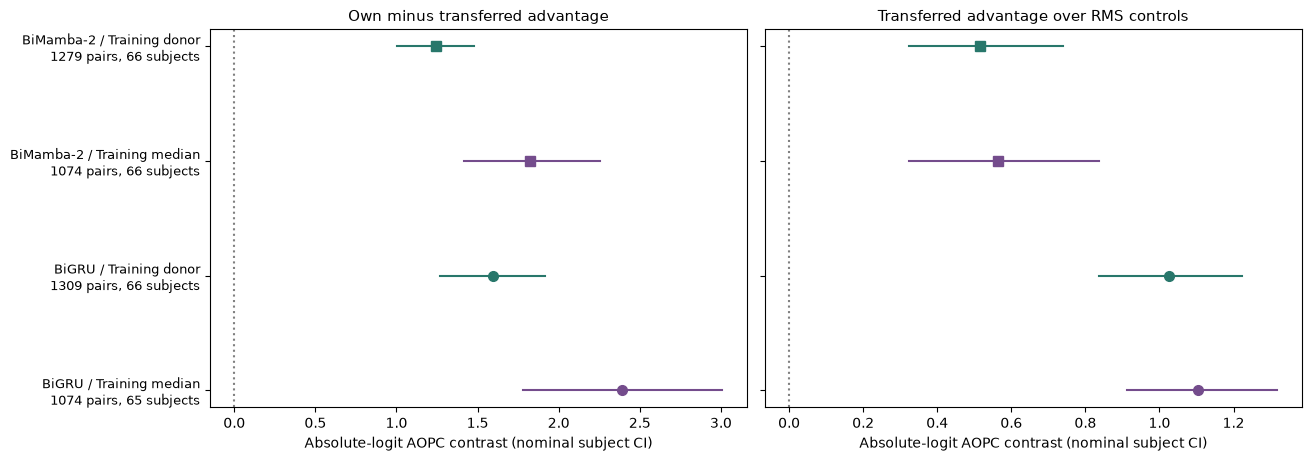

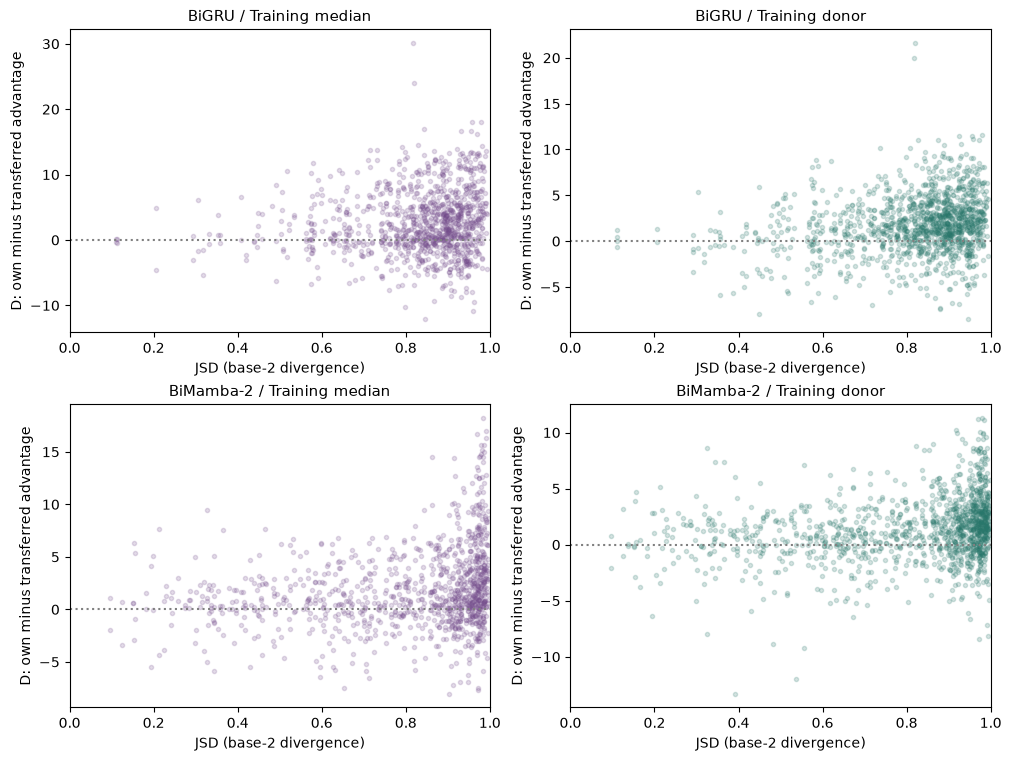

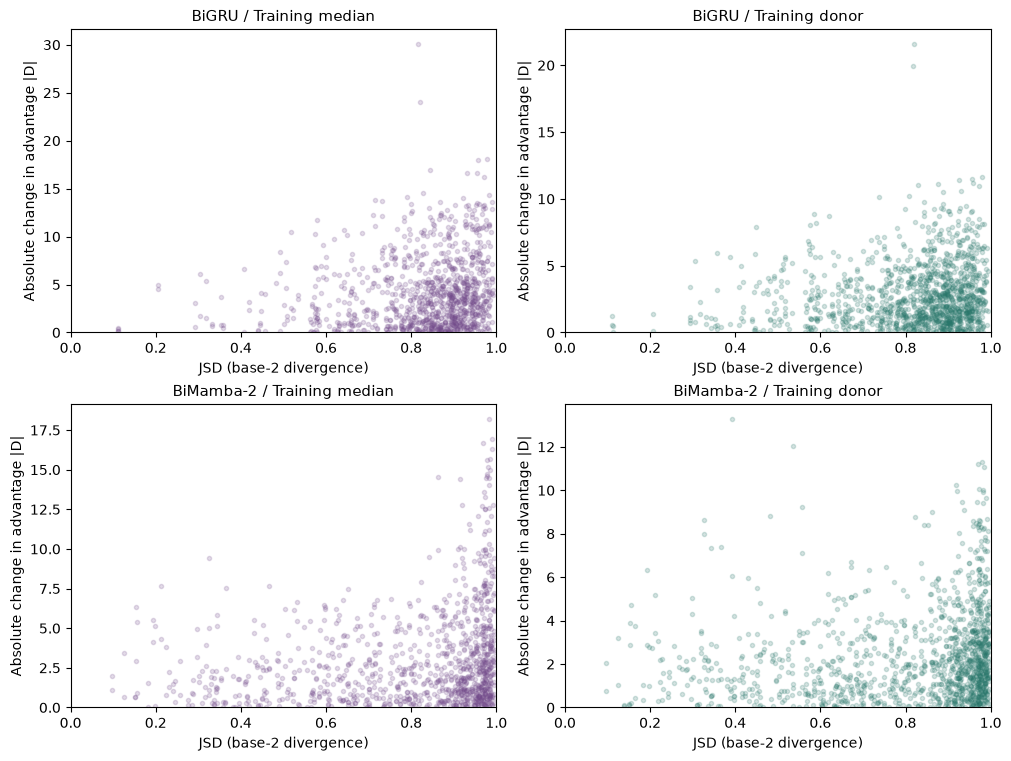

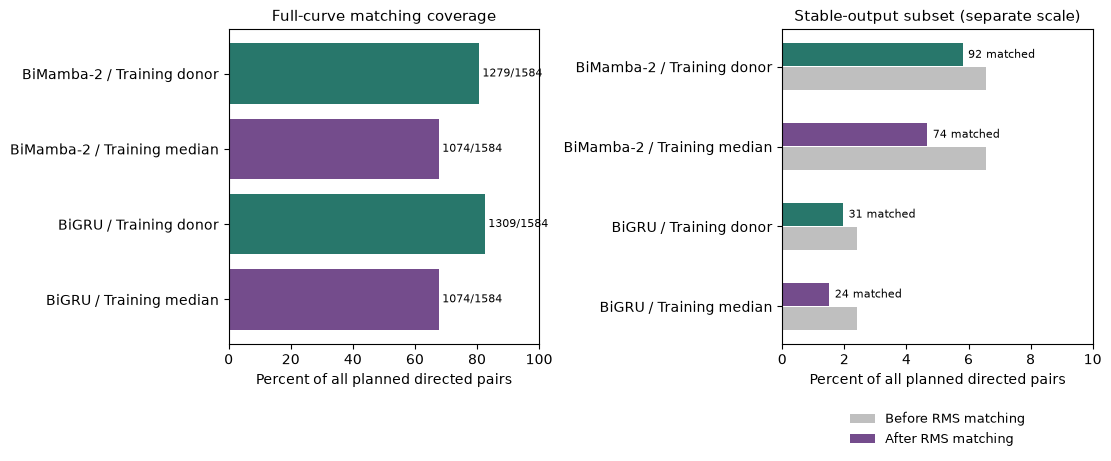

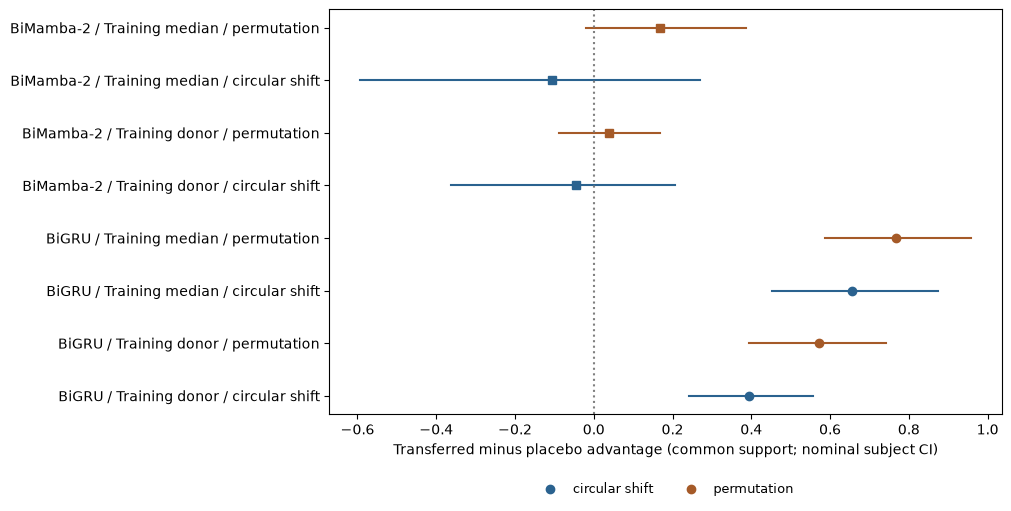

In [18]:
ARM_LABEL={'gru':'BiGRU','mamba2':'BiMamba-2'}
MASK_LABEL={'train_median':'Training median','train_donor':'Training donor'}
MASK_COLOR={'train_median':'#744c8c','train_donor':'#28776b'}
MARKER={'gru':'o','mamba2':'s'}
strata=[(arm,masker) for arm in ARMS for masker in MASKERS]
labels=[ARM_LABEL[a]+' / '+MASK_LABEL[m] for a,m in strata]
fig,axes=plt.subplots(1,2,figsize=(13,4.5),layout='constrained',sharey=True)
secondary=pd.DataFrame(secondary_rows)
for j,(endpoint,title) in enumerate([('D','Own minus transferred advantage'),('G_swap','Transferred advantage over RMS controls')]):
    source=primary if endpoint=='D' else secondary[(secondary.endpoint=='G_swap')&(secondary.scenario=='all_pairs')]
    for i,(arm,masker) in enumerate(strata):
        row=source[(source.architecture==arm)&(source.masker==masker)].iloc[0]
        if np.isfinite(row.estimate):
            axes[j].plot(row.estimate,i,MARKER[arm],color=MASK_COLOR[masker],ms=7)
            if np.isfinite(row.ci_low):axes[j].plot([row.ci_low,row.ci_high],[i,i],color=MASK_COLOR[masker],lw=1.5)
    axes[j].axvline(0,color='.5',ls=':');axes[j].set(title=title,xlabel='Absolute-logit AOPC contrast (nominal subject CI)')
count_labels=[]
for arm,masker in strata:
    row=primary[(primary.architecture==arm)&(primary.masker==masker)].iloc[0]
    count_labels.append(ARM_LABEL[arm]+' / '+MASK_LABEL[masker]
                        +f'\n{int(row.n_pairs)} pairs, {int(row.n_subjects)} subjects')
axes[0].set_yticks(range(len(strata)),count_labels,fontsize=9)
save_figure(fig,'fixed_model_swap_primary')

fig,axes=plt.subplots(2,2,figsize=(10,7.5),layout='constrained')
for i,arm in enumerate(ARMS):
    for j,masker in enumerate(MASKERS):
        g=pair_curves[(pair_curves.architecture==arm)&(pair_curves.masker==masker)&pair_curves.pair_eligible]
        axes[i,j].scatter(g.js_divergence,g.D,s=9,alpha=.2,color=MASK_COLOR[masker],rasterized=True)
        axes[i,j].axhline(0,color='.5',ls=':')
        axes[i,j].set(xlim=(0,1),xlabel='JSD (base-2 divergence)',ylabel='D: own minus transferred advantage',
                      title=ARM_LABEL[arm]+' / '+MASK_LABEL[masker])
save_figure(fig,'jsd_vs_signed_swap_effect')
fig,axes=plt.subplots(2,2,figsize=(10,7.5),layout='constrained')
for i,arm in enumerate(ARMS):
    for j,masker in enumerate(MASKERS):
        g=pair_curves[(pair_curves.architecture==arm)&(pair_curves.masker==masker)&pair_curves.pair_eligible]
        axes[i,j].scatter(g.js_divergence,g.abs_D,s=9,alpha=.2,color=MASK_COLOR[masker],rasterized=True)
        axes[i,j].set(xlim=(0,1),ylim=(0,None),xlabel='JSD (base-2 divergence)',ylabel='Absolute change in advantage |D|',
                      title=ARM_LABEL[arm]+' / '+MASK_LABEL[masker])
save_figure(fig,'jsd_vs_absolute_swap_effect')

fig,axes=plt.subplots(1,2,figsize=(11,4.5),layout='constrained')
position=np.arange(len(strata))
for i,(arm,masker) in enumerate(strata):
    row=coverage[(coverage.architecture==arm)&(coverage.masker==masker)].iloc[0]
    matched=100*row.n_pairs_matched/row.n_pairs_total
    before=100*row.n_pairs_stable_before_matching/row.n_pairs_total
    after=100*row.n_pairs_stable_after_matching/row.n_pairs_total
    axes[0].barh(i,matched,color=MASK_COLOR[masker])
    axes[0].text(min(matched+1,92),i,f'{int(row.n_pairs_matched)}/{int(row.n_pairs_total)}',va='center',fontsize=8)
    axes[1].barh(i-.15,before,height=.28,color='.75',label='Before RMS matching' if i==0 else None)
    axes[1].barh(i+.15,after,height=.28,color=MASK_COLOR[masker],label='After RMS matching' if i==0 else None)
    axes[1].annotate(f'{int(row.n_pairs_stable_after_matching)} matched',(after,i+.15),xytext=(4,0),
                     textcoords='offset points',va='center',fontsize=8)
axes[0].set(xlim=(0,100),xlabel='Percent of all planned directed pairs',title='Full-curve matching coverage')
maximum=max([100*r.n_pairs_stable_before_matching/r.n_pairs_total for r in coverage.itertuples(index=False)],default=0)
axes[1].set(xlim=(0,max(10,maximum*1.4)),xlabel='Percent of all planned directed pairs',title='Stable-output subset (separate scale)')
for ax in axes:ax.set_yticks(position,labels)
axes[1].legend(loc='upper center',bbox_to_anchor=(.5,-.18),frameon=False,ncol=1)
save_figure(fig,'swap_matching_and_stable_coverage')

fig,ax=plt.subplots(figsize=(10,5),layout='constrained')
reference_plot=reference_ci[reference_ci.endpoint=='G_real_minus_placebo']
legend_done=set();yticks=[]
for i,row in enumerate(reference_plot.itertuples(index=False)):
    color='#2a628f' if row.reference=='circular_shift' else '#a55a28'
    label=row.reference.replace('_',' ') if row.reference not in legend_done else None
    if np.isfinite(row.estimate):
        ax.plot(row.estimate,i,MARKER[row.architecture],color=color,label=label)
        if np.isfinite(row.ci_low):ax.plot([row.ci_low,row.ci_high],[i,i],color=color)
    legend_done.add(row.reference)
    yticks.append(ARM_LABEL[row.architecture]+' / '+MASK_LABEL[row.masker]+' / '+row.reference.replace('_',' '))
ax.set_yticks(range(len(yticks)),yticks);ax.axvline(0,color='.5',ls=':')
ax.set(xlabel='Transferred minus placebo advantage (common support; nominal subject CI)')
ax.legend(loc='upper center',bbox_to_anchor=(.5,-.14),ncol=2,frameon=False)
save_figure(fig,'swap_vs_jsd_matched_references')

## Completion and interpretation

Inspect `analysis_manifest.json` and `alignment_checks.csv` first, then self-swap,
replay, matching/coverage and dose tables. Primary `D` contrasts and G_swap use
the same eligible support. A positive mean G_swap is an above-control response
under the tested replacements; mean D near zero is not an equivalence result.
Reference contrasts use an additional common-support restriction. Inspect its
losses before interpreting a reference comparison.

`control_reweighting_sensitivity.csv` reports conditional finite-pool quantiles,
not subject CIs or uncertainty of drawing a fresh matching search. Three training
seeds remain three seeds; subject CIs condition on this bank. Secondary intervals
are exploratory and nominal. Save this run's whole results directory when sharing
results. Training-seed/UCI replication is a later, separately locked protocol.

In [19]:
check(source_digest(NOTEBOOK)==SOURCE_DIGEST,'new notebook scientific source unchanged')
inventory=[]
for path,before in sorted(tracked.items(),key=lambda item:str(item[0])):
    after=file_hash(path)
    inventory.append(dict(path=str(path.relative_to(ROOT)),sha256_before=before,
                          sha256_after=after,unchanged=before==after))
inventory=pd.DataFrame(inventory)
inventory.to_csv(OUT/'input_inventory.csv',index=False)
check(inventory.unchanged.all(),'all original input/source files unchanged')
pd.DataFrame(checks).to_csv(OUT/'alignment_checks.csv',index=False)
run_manifest.update(completion_status='complete',completed_utc=datetime.now(timezone.utc).isoformat(),
    scientific_source=str(NOTEBOOK.relative_to(ROOT)),notebook_source_sha256=SOURCE_DIGEST,
    source_pins_sha256=file_hash(PLAN/'source_pins.json'),protocol_sha256=file_hash(PLAN/'PROTOCOL.md'),
    versions={name:version(name) for name in ('numpy','pandas','scipy','matplotlib')},
    python=platform.python_version(),tables=sorted(p.name for p in OUT.glob('*.csv')),
    figures=sorted(p.name for p in FIG.glob('*')),old_preregistration_changed=False,
    alignment_checks_total=len(checks),alignment_checks_passed=sum(int(c['passed']) for c in checks),
    n_input_files_tracked=len(inventory),bank=dict(cohort=recipe['cohort'],architectures=list(ARMS),
        seeds=list(SEEDS),n_checkpoints=len(models),n_records=len(records),n_subjects=len(subjects)))
(OUT/'analysis_manifest.json').write_text(json.dumps(run_manifest,indent=2),encoding='utf-8')
print('COMPLETE:',OUT)
print('Additional exploratory results; historical estimates and manuscript untouched.')

COMPLETE: /home/agribychaniago/Python Projects/Skripsi/results/attention_ranking_swap/20261017T002514477657Z
Additional exploratory results; historical estimates and manuscript untouched.
